# 279. Dark proteins kmerseek puts a region on, at E < 1 and E < 10

> **Query-summary repair completed 2026-10-23.** Sections 2-6 now read the repaired
> summaries from the completed Sherlock run. The old awk reduction could keep `inf`
> instead of a finite minimum. Human hp_lehninger2 k17 at scaled 1 now reaches 545 dark
> proteins at E < 1, matching the independent region-file count; the original export
> counted 444. Section 9 retains that original export only to show the correction.
> `scripts/export_nb279_repaired_queries.py` rebuilds the tables from the repaired
> query summaries without new searches. Input/output hashes and source directories are
> in `tables/279_repaired_export_manifest.json.gz`.

**Question.** A protein is *dark* when phmmer, jackhmmer (3 iterations) and mmseqs2 all fail
to find a hit for it in Swiss-Prot with the query species' own clade removed. For each
kmerseek alphabet and k-size, what share of the dark proteins does kmerseek put a region on,
and how does that compare with the share of *placed* proteins (every protein that is not
dark) it puts a region on?

Both questions use one E-value cutoff for everything, as Olga asked on 2026-10-12: a protein
is dark at cutoff E when no tool has a hit with E-value below E, and kmerseek *reaches* a
protein at cutoff E when one of its regions has an E-value below E. The cutoffs are set in
the first code cell; change them there and re-run to try others. Nothing is searched again.

**How to read it.** Reaching a protein is not the same as finding its homolog: at E < 10
chance alone puts a region on most proteins. So a setting's dark share means something only
next to its placed share. Placed proteins have a conventional-tool hit at the same cutoff; weak hits may be false.
A useful setting should reach this comparator-positive group more often than dark proteins. A setting that reaches both at the
same rate is reporting something for everything.

**Decision.** Whether the dark set has candidates worth the structure check (the expensive
next step of the dark-set pipeline), and at which cutoff. The rule, written before the E < 1
and E < 10 kmerseek numbers were computed:

* A setting *tells dark from placed* when its placed share is at least twice its dark share.
* At a cutoff, the dark set has candidates if, in **all five species**, at least one setting
  that tells dark from placed reaches **at least 5%** of the dark proteins.
* If yes, we take the dark proteins those settings reach to the structure check. If no, the
  dark-set claim has no candidates at that cutoff.

The E-value cutoff of 0.01 was looked at before this rule was written (median dark share
about 0, best setting 6-9%, under the pipeline's dark set at E <= 0.001).

**Data.** The invertebrate dark-set midi run (`runs/ladder-0.4-midi`, finished 2026-10-12
13:04 on Sherlock; [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57),
commit e3808d1), image `olgabot/kmerseek:0.4.0-rc5`.

* Queries: five proteomes. Human (UniProt UP000005640), worm *C. elegans* (UP000001940),
  yeast *S. cerevisiae* S288C (UP000002311), *Borreliella burgdorferi* B31 (UP000001807) and
  *Botryllus schlosseri* (gene models, 45_339 proteins).
* Target: reviewed Swiss-Prot with the query's clade removed: Mammalia, Chromadorea,
  Saccharomycetes, Spirochaetia and Ascidiacea.
* kmerseek: 115 alphabet and k-size pairs (every other k from notebook 274's k_min to k_max,
  minus the pairs dropped in PR 57), at scaled 1 and 10, each extended through mismatches at
  its alphabet's own mismatch penalty, so every region has a Karlin-Altschul E-value.
  Settings whose index holds no Karlin-Altschul fit have no E-values and are left out.
* The repaired kmerseek minima come from `scripts/export_nb279_repaired_queries.py`,
  reading completed repaired query summaries from PR 57. Conventional-tool minima are
  copied byte-for-byte from the original export at ac5e4f9; those searches did not change.
  Their reporting cutoff was E = 10, so every reported hit below 10 is retained.
* The low-complexity mask was off for every kmerseek search in this run.

In [1]:
# The toggle. Each pair is (cutoff for the tools that define dark, cutoff for kmerseek).
# A protein counts below a cutoff when its E-value is strictly less than it.
CUTOFF_PAIRS = [(1, 1), (10, 10)]
SCALED = 1  # 1 or 10: which kmerseek index setting to draw
MIN_PLACED_OVER_DARK = 2  # "tells dark from placed": placed share >= 2 x dark share
MIN_DARK_SHARE = 0.05  # "has candidates": at least 5% of dark proteins reached

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_cols(-1)

DATA = Path(
    "/Users/olga/data/invertebrate-dark-set/results-0.4/protein-evalues-repaired-2026-10-23"
)
import json

export_manifest = json.loads((DATA / "manifest.json").read_text())
print(
    "Repaired source settings:",
    {
        s: {k: v for k, v in r.items() if k.startswith("n_")}
        for s, r in export_manifest["species"].items()
    },
)
FIG = Path("../figures")
TABLES = Path("../tables")
SPECIES = ["human", "worm", "yeast", "borrelia", "botryllus"]
SPECIES_NAME = {
    "human": "Human",
    "worm": "C. elegans",
    "yeast": "S. cerevisiae",
    "borrelia": "B. burgdorferi",
    "botryllus": "B. schlosseri",
}
TOOLS = ["phmmer", "jackhmmer", "mmseqs2"]

missing = [
    s for s in SPECIES if not (DATA / f"{s}_protein_tool_min_evalue.csv.gz").exists()
]
if missing:
    raise SystemExit(
        f"Copy the export for {missing} from Sherlock into {DATA} first "
        "(see tools/export-protein-evalues on PR 57)."
    )

tool = pl.concat(
    [
        pl.read_csv(
            DATA / f"{s}_protein_tool_min_evalue.csv.gz", infer_schema_length=0
        ).with_columns(pl.col(TOOLS).cast(pl.Float64), pl.lit(s).alias("species"))
        for s in SPECIES
    ]
)
# Smallest E-value over the three tools; null when no tool reported any hit
tool = tool.with_columns(pl.min_horizontal(TOOLS).alias("best_tool_evalue"))
km = pl.concat(
    [
        pl.read_csv(
            DATA / f"{s}_protein_kmerseek_min_evalue.csv.gz",
            schema_overrides={"accession": pl.String},
        ).with_columns(pl.lit(s).alias("species"))
        for s in SPECIES
    ]
)
unfitted = pl.concat(
    [
        pl.read_csv(DATA / f"{s}_kmerseek_unfitted.csv").with_columns(
            pl.lit(s).alias("species")
        )
        for s in SPECIES
    ]
)
print(
    tool.group_by("species")
    .agg(
        pl.len().alias("proteins"),
        pl.col("best_tool_evalue").is_null().sum().alias("no_tool_hit_at_all"),
    )
    .sort(pl.col("species").replace_strict({s: i for i, s in enumerate(SPECIES)}))
)
print(
    km.group_by("species", "scaled")
    .agg(
        pl.struct("alphabet", "ksize").n_unique().alias("settings_with_evalues"),
        pl.len().alias("protein_setting_rows"),
    )
    .sort("species", "scaled")
)
print(
    unfitted.filter(pl.col("scaled") == SCALED)
    .group_by("species")
    .agg(pl.len().alias(f"settings_without_fit_scaled_{SCALED}"))
)

Repaired source settings: {'human': {'n_proteins': 20600, 'n_source_files': 2530, 'n_settings_searched': 167, 'n_settings_refused': 63, 'n_output_rows': 3015970}, 'worm': {'n_proteins': 19819, 'n_source_files': 2300, 'n_settings_searched': 169, 'n_settings_refused': 61, 'n_output_rows': 2667849}, 'yeast': {'n_proteins': 6049, 'n_source_files': 920, 'n_settings_searched': 165, 'n_settings_refused': 65, 'n_output_rows': 840639}, 'borrelia': {'n_proteins': 1291, 'n_source_files': 230, 'n_settings_searched': 174, 'n_settings_refused': 56, 'n_output_rows': 175140}, 'botryllus': {'n_proteins': 45339, 'n_source_files': 5290, 'n_settings_searched': 168, 'n_settings_refused': 62, 'n_output_rows': 5896709}}


┌───────────┬──────────┬────────────────────┐
│ species   ┆ proteins ┆ no_tool_hit_at_all │
│ ---       ┆ ---      ┆ ---                │
│ str       ┆ u32      ┆ u32                │
╞═══════════╪══════════╪════════════════════╡
│ human     ┆ 20600    ┆ 303                │
│ worm      ┆ 19819    ┆ 481                │
│ yeast     ┆ 6049     ┆ 83                 │
│ borrelia  ┆ 1291     ┆ 17                 │
│ botryllus ┆ 45339    ┆ 876                │
└───────────┴──────────┴────────────────────┘


┌───────────┬────────┬───────────────────────┬──────────────────────┐
│ species   ┆ scaled ┆ settings_with_evalues ┆ protein_setting_rows │
│ ---       ┆ ---    ┆ ---                   ┆ ---                  │
│ str       ┆ i64    ┆ u32                   ┆ u32                  │
╞═══════════╪════════╪═══════════════════════╪══════════════════════╡
│ borrelia  ┆ 1      ┆ 89                    ┆ 103562               │
│ borrelia  ┆ 10     ┆ 85                    ┆ 71578                │
│ botryllus ┆ 1      ┆ 86                    ┆ 3453922              │
│ botryllus ┆ 10     ┆ 82                    ┆ 2442787              │
│ human     ┆ 1      ┆ 88                    ┆ 1721184              │
│ human     ┆ 10     ┆ 79                    ┆ 1294786              │
│ worm      ┆ 1      ┆ 88                    ┆ 1575891              │
│ worm      ┆ 10     ┆ 81                    ┆ 1091958              │
│ yeast     ┆ 1      ┆ 85                    ┆ 479489               │
│ yeast     ┆ 10    

## 1. How many proteins are dark at each cutoff

A protein is dark at cutoff E when none of phmmer, jackhmmer and mmseqs2 has a hit for it
with an E-value below E. A larger cutoff accepts weaker hits, so fewer proteins stay dark.
The pipeline's own dark set used E <= 0.001; it is drawn for comparison. Here the cutoff is
strict (E < 0.001), so a protein whose best hit is exactly E = 0.001 is dark here and placed
in the pipeline: that is one protein in human (3_103 here, 3_102 there) and one in
*B. schlosseri* (20_449 against 20_448).

┌───────────┬─────────────┬──────────┬───────┬────────────┐
│ species   ┆ tool_cutoff ┆ proteins ┆ dark  ┆ dark_share │
│ ---       ┆ ---         ┆ ---      ┆ ---   ┆ ---        │
│ str       ┆ f64         ┆ u32      ┆ u32   ┆ f64        │
╞═══════════╪═════════════╪══════════╪═══════╪════════════╡
│ human     ┆ 0.001       ┆ 20600    ┆ 3103  ┆ 0.151      │
│ human     ┆ 1.0         ┆ 20600    ┆ 1696  ┆ 0.082      │
│ human     ┆ 10.0        ┆ 20600    ┆ 442   ┆ 0.021      │
│ worm      ┆ 0.001       ┆ 19819    ┆ 8915  ┆ 0.45       │
│ worm      ┆ 1.0         ┆ 19819    ┆ 4667  ┆ 0.235      │
│ worm      ┆ 10.0        ┆ 19819    ┆ 798   ┆ 0.04       │
│ yeast     ┆ 0.001       ┆ 6049     ┆ 1299  ┆ 0.215      │
│ yeast     ┆ 1.0         ┆ 6049     ┆ 725   ┆ 0.12       │
│ yeast     ┆ 10.0        ┆ 6049     ┆ 157   ┆ 0.026      │
│ borrelia  ┆ 0.001       ┆ 1291     ┆ 612   ┆ 0.474      │
│ borrelia  ┆ 1.0         ┆ 1291     ┆ 292   ┆ 0.226      │
│ borrelia  ┆ 10.0        ┆ 1291     ┆ 5

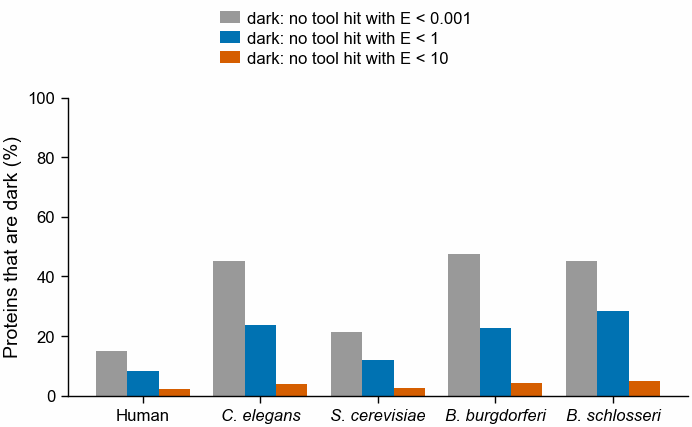

In [3]:
def dark_flags(tool_cutoff):
    # True when no tool hit has E < tool_cutoff
    return tool.select(
        "species",
        "accession",
        (
            pl.col("best_tool_evalue").is_null()
            | (pl.col("best_tool_evalue") >= tool_cutoff)
        ).alias("dark"),
    )


tool_cutoffs = sorted({0.001, *(t for t, _ in CUTOFF_PAIRS)})
dark_counts = pl.concat(
    [
        dark_flags(t)
        .group_by("species")
        .agg(pl.len().alias("proteins"), pl.col("dark").sum().alias("dark"))
        .with_columns(pl.lit(t).cast(pl.Float64).alias("tool_cutoff"))
        for t in tool_cutoffs
    ]
).with_columns((pl.col("dark") / pl.col("proteins")).alias("dark_share"))
order = {s: i for i, s in enumerate(SPECIES)}
dark_counts = dark_counts.sort(pl.col("species").replace_strict(order), "tool_cutoff")
print(
    dark_counts.select(
        "species", "tool_cutoff", "proteins", "dark", pl.col("dark_share").round(3)
    )
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
colours = [
    pf.GREY,
    pf.OKABE_ITO["blue"],
    pf.OKABE_ITO["vermillion"],
    pf.OKABE_ITO["bluish_green"],
]
width = 0.8 / len(tool_cutoffs)
for j, t in enumerate(tool_cutoffs):
    d = dark_counts.filter(pl.col("tool_cutoff") == t)
    xs = [order[s] + (j - (len(tool_cutoffs) - 1) / 2) * width for s in d["species"]]
    ax.bar(
        xs,
        100 * d["dark_share"],
        width=width,
        color=colours[j % len(colours)],
        label=f"dark: no tool hit with E < {t:g}",
    )
ax.set_xticks(range(len(SPECIES)), [SPECIES_NAME[s] for s in SPECIES])
for lab in ax.get_xticklabels():
    lab.set_fontstyle("italic" if lab.get_text() != "Human" else "normal")
ax.set_ylabel("Proteins that are dark (%)")
ax.set_ylim(0, 100)
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "279_dark_share_by_tool_evalue_qfo_swissprot")

## 2. Share of dark and of placed proteins each kmerseek setting reaches

One panel per species (columns) and per cutoff pair (rows). Each point is one kmerseek
alphabet and k-size at the chosen `SCALED`. x: share of the placed proteins it puts a region
on with E below the cutoff. y: the same for the dark proteins. A point on the grey diagonal
reaches dark and placed proteins equally often, so it does not tell them apart. The dashed
line is placed share = 2 x dark share: points below it tell dark from placed under this
notebook's rule. Points high on the y-axis and below the dashed line are the candidates.

Three settings with the largest dark share, per species and cutoff:
┌─────────────┬─────────────────┬───────────┬───────────────────┬───────┬───────────────┬──────────────┬────────────┬─────────────────┬────────────────┬──────────────┬────────────────────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species   ┆ alphabet          ┆ ksize ┆ dark_proteins ┆ dark_reached ┆ dark_share ┆ placed_proteins ┆ placed_reached ┆ placed_share ┆ tells_dark_from_placed │
│ ---         ┆ ---             ┆ ---       ┆ ---               ┆ ---   ┆ ---           ┆ ---          ┆ ---        ┆ ---             ┆ ---            ┆ ---          ┆ ---                    │
│ f64         ┆ f64             ┆ str       ┆ str               ┆ i64   ┆ u32           ┆ u32          ┆ f64        ┆ u32             ┆ u32            ┆ f64          ┆ bool                   │
╞═════════════╪═════════════════╪═══════════╪═══════════════════╪═══════╪═══════════════╪══════════════╪════════════╪═════════════════╪════════════════╪════════

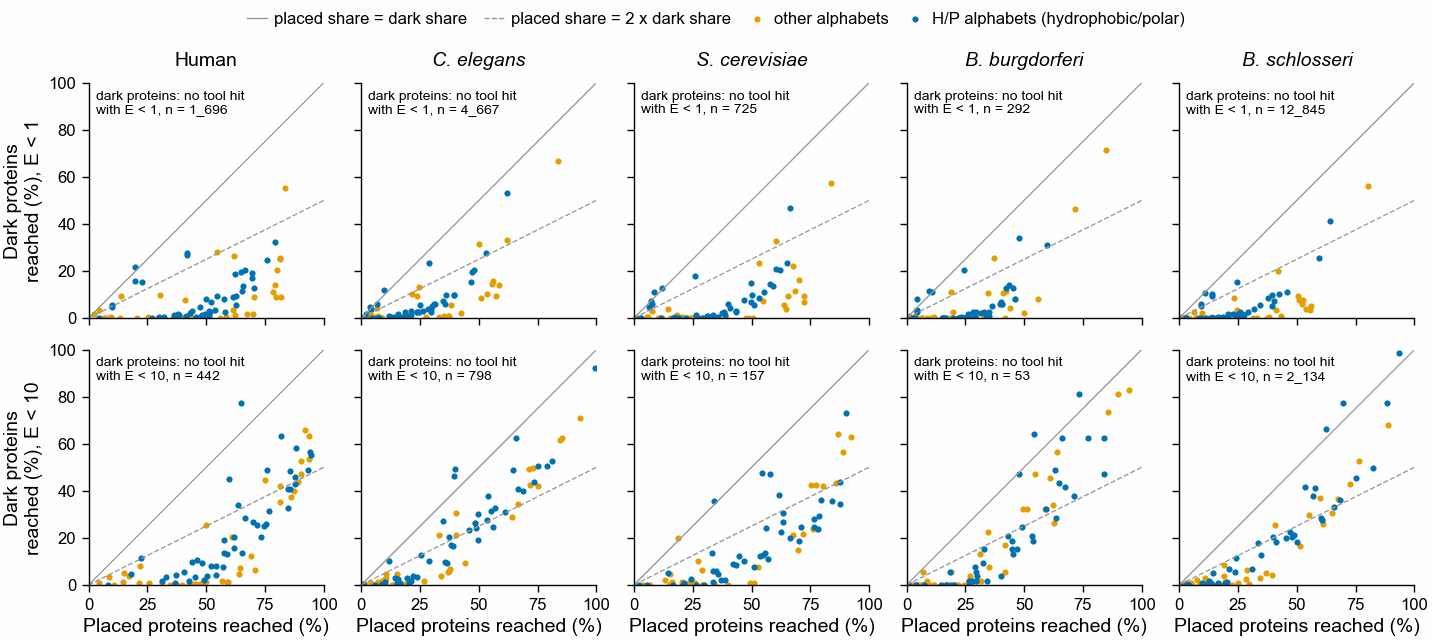

In [4]:
def reach(tool_cutoff, km_cutoff, scaled=SCALED):
    # Per species and setting: dark and placed proteins, and how many of each kmerseek reaches
    flags = dark_flags(tool_cutoff)
    sizes = flags.group_by("species").agg(
        pl.col("dark").sum().alias("dark_proteins"),
        (~pl.col("dark")).sum().alias("placed_proteins"),
    )
    hit = km.filter(
        (pl.col("scaled") == scaled) & (pl.col("min_region_evalue") < km_cutoff)
    ).join(flags, on=["species", "accession"], how="left")
    if hit["dark"].null_count():
        raise ValueError("kmerseek reached a protein that is not in the tool table")
    settings = (
        km.filter(pl.col("scaled") == scaled)
        .select("species", "alphabet", "ksize")
        .unique()
    )
    counts = hit.group_by("species", "alphabet", "ksize").agg(
        pl.col("dark").sum().alias("dark_reached"),
        (~pl.col("dark")).sum().alias("placed_reached"),
    )
    out = (
        settings.join(counts, on=["species", "alphabet", "ksize"], how="left")
        .with_columns(pl.col("dark_reached", "placed_reached").fill_null(0))
        .join(sizes, on="species")
        .with_columns(
            (pl.col("dark_reached") / pl.col("dark_proteins")).alias("dark_share"),
            (pl.col("placed_reached") / pl.col("placed_proteins")).alias(
                "placed_share"
            ),
            pl.lit(tool_cutoff).cast(pl.Float64).alias("tool_cutoff"),
            pl.lit(km_cutoff).cast(pl.Float64).alias("kmerseek_cutoff"),
            pl.lit(scaled).alias("scaled"),
        )
    )
    return out.with_columns(
        (pl.col("placed_share") >= MIN_PLACED_OVER_DARK * pl.col("dark_share")).alias(
            "tells_dark_from_placed"
        )
    )


reach_all = pl.concat([reach(t, k) for t, k in CUTOFF_PAIRS])
reach_all = reach_all.with_columns(
    pl.col("alphabet").str.starts_with("hp_").alias("hp_alphabet")
)
TABLES.mkdir(exist_ok=True)
reach_all.sort("tool_cutoff", "species", "alphabet", "ksize").write_csv(
    TABLES / f"279_dark_set_kmerseek_reach_scaled{SCALED}_qfo_swissprot.csv"
)

top = (
    reach_all.sort(
        ["dark_share", "placed_share", "alphabet", "ksize"],
        descending=[True, True, False, False],
    )
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", maintain_order=True)
    .head(3)
    .sort(
        "tool_cutoff",
        pl.col("species").replace_strict(order),
        pl.col("dark_share"),
        descending=[False, False, True],
    )
)
print("Three settings with the largest dark share, per species and cutoff:")
print(
    top.select(
        "tool_cutoff",
        "kmerseek_cutoff",
        "species",
        "alphabet",
        "ksize",
        "dark_proteins",
        "dark_reached",
        pl.col("dark_share").round(3),
        "placed_proteins",
        "placed_reached",
        pl.col("placed_share").round(3),
        "tells_dark_from_placed",
    )
)

n_rows = len(CUTOFF_PAIRS)
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM,
    34 * n_rows + 14,
    nrows=n_rows,
    ncols=len(SPECIES),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for r, (t, k) in enumerate(CUTOFF_PAIRS):
    for c, s in enumerate(SPECIES):
        ax = axs[r][c]
        d = reach_all.filter(
            (pl.col("tool_cutoff") == t)
            & (pl.col("kmerseek_cutoff") == k)
            & (pl.col("species") == s)
        )
        ax.plot(
            [0, 100], [0, 100], color=pf.GREY, lw=0.5, label="placed share = dark share"
        )
        ax.plot(
            [0, 100],
            [0, 100 / MIN_PLACED_OVER_DARK],
            color=pf.GREY,
            lw=0.5,
            ls="--",
            label=f"placed share = {MIN_PLACED_OVER_DARK} x dark share",
        )
        for is_hp, colour, name in [
            (False, pf.OKABE_ITO["orange"], "other alphabets"),
            (True, pf.OKABE_ITO["blue"], "H/P alphabets (hydrophobic/polar)"),
        ]:
            e = d.filter(pl.col("hp_alphabet") == is_hp)
            ax.scatter(
                100 * e["placed_share"],
                100 * e["dark_share"],
                s=5,
                color=colour,
                lw=0,
                label=name,
            )
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)
        if r == 0:
            ax.set_title(
                SPECIES_NAME[s], fontstyle="normal" if s == "human" else "italic"
            )
        if c == 0:
            ax.set_ylabel(f"Dark proteins\nreached (%), E < {k:g}")
        if r == n_rows - 1:
            ax.set_xlabel(f"Placed proteins reached (%)")
        ax.text(
            0.03,
            0.97,
            f"dark proteins: no tool hit\nwith E < {t:g}, n = {d['dark_proteins'][0]:_}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=5,
        )
pf.shared_legend(fig, ncol=4)
pf.save(fig, FIG / f"279_dark_vs_placed_reach_scaled{SCALED}_qfo_swissprot")

## 3. Does any setting have candidates, under the rule

For each species and cutoff, the setting with the largest dark share among the settings that
tell dark from placed (placed share at least twice the dark share). The bars are that
setting's dark share; the dashed line is the 5% the rule asks for. The setting is named under
each bar.

┌─────────────┬─────────────────┬───────────┬──────────────────────────┬───────┬───────────────┬──────────────┬────────────┬────────────────┬──────────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species   ┆ alphabet                 ┆ ksize ┆ dark_proteins ┆ dark_reached ┆ dark_share ┆ placed_reached ┆ placed_share │
│ ---         ┆ ---             ┆ ---       ┆ ---                      ┆ ---   ┆ ---           ┆ ---          ┆ ---        ┆ ---            ┆ ---          │
│ f64         ┆ f64             ┆ str       ┆ str                      ┆ i64   ┆ u32           ┆ u32          ┆ f64        ┆ u32            ┆ f64          │
╞═════════════╪═════════════════╪═══════════╪══════════════════════════╪═══════╪═══════════════╪══════════════╪════════════╪════════════════╪══════════════╡
│ 1.0         ┆ 1.0             ┆ human     ┆ hp_lehninger2            ┆ 17    ┆ 1696          ┆ 545          ┆ 0.321      ┆ 15015          ┆ 0.794        │
│ 1.0         ┆ 1.0             ┆ worm      ┆ hp_lehninger

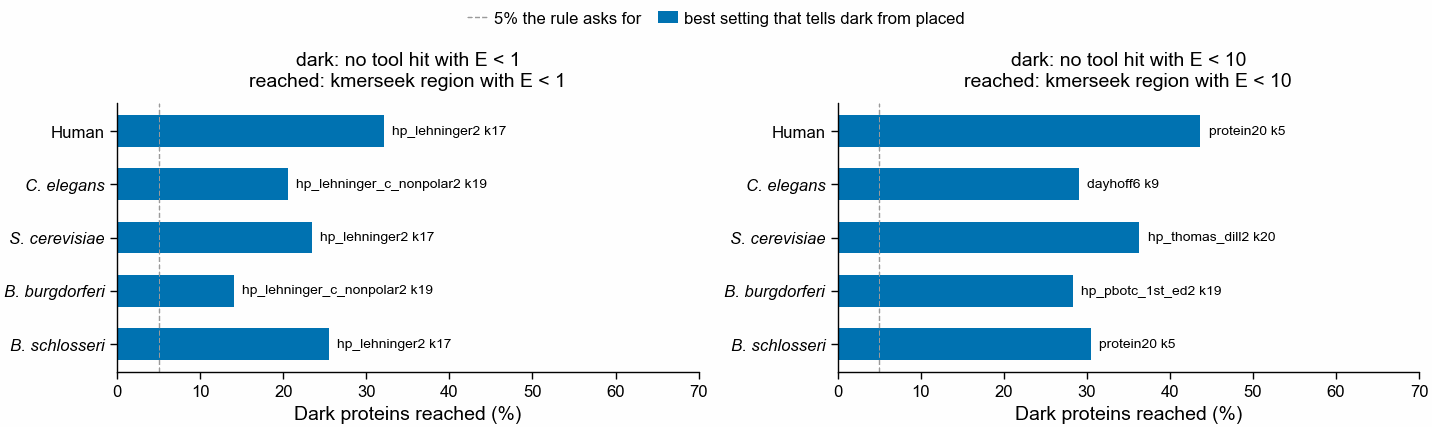

In [5]:
best = (
    reach_all.filter(pl.col("tells_dark_from_placed"))
    .sort(
        ["dark_share", "placed_share", "alphabet", "ksize"],
        descending=[True, True, False, False],
    )
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", maintain_order=True)
    .head(1)
)
grid = pl.DataFrame(
    [
        {"tool_cutoff": float(t), "kmerseek_cutoff": float(k), "species": s}
        for t, k in CUTOFF_PAIRS
        for s in SPECIES
    ]
)
best = grid.join(
    best, on=["tool_cutoff", "kmerseek_cutoff", "species"], how="left"
).with_columns(pl.col("dark_share").fill_null(0.0), pl.col("dark_reached").fill_null(0))
print(
    best.select(
        "tool_cutoff",
        "kmerseek_cutoff",
        "species",
        "alphabet",
        "ksize",
        "dark_proteins",
        "dark_reached",
        pl.col("dark_share").round(3),
        "placed_reached",
        pl.col("placed_share").round(3),
    )
)

best.write_csv(TABLES / f"279_repaired_best_qualifying_settings_scaled{SCALED}.csv")

verdict = (
    best.group_by("tool_cutoff", "kmerseek_cutoff")
    .agg(
        (pl.col("dark_share") >= MIN_DARK_SHARE).sum().alias("species_with_candidates"),
        pl.len().alias("species"),
    )
    .sort("tool_cutoff")
)
verdict = verdict.with_columns(
    (pl.col("species_with_candidates") == pl.col("species")).alias("rule_met")
)
print(verdict)

fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 55, ncols=len(CUTOFF_PAIRS), sharex=True, squeeze=False
)
for c, (t, k) in enumerate(CUTOFF_PAIRS):
    ax = axs[0][c]
    d = best.filter(
        (pl.col("tool_cutoff") == t) & (pl.col("kmerseek_cutoff") == k)
    ).sort(pl.col("species").replace_strict(order))
    ys = list(range(len(SPECIES)))[::-1]
    ax.barh(
        ys,
        100 * d["dark_share"],
        color=pf.OKABE_ITO["blue"],
        height=0.6,
        label="best setting that tells dark from placed",
    )
    ax.axvline(
        100 * MIN_DARK_SHARE,
        color=pf.GREY,
        lw=0.5,
        ls="--",
        label=f"{100 * MIN_DARK_SHARE:g}% the rule asks for",
    )
    for y, share, a, kk in zip(ys, d["dark_share"], d["alphabet"], d["ksize"]):
        ax.text(
            100 * share + 1,
            y,
            f"{a} k{kk}" if a is not None else "none",
            va="center",
            fontsize=5,
        )
    ax.set_yticks(ys, [SPECIES_NAME[s] for s in d["species"]])
    for lab in ax.get_yticklabels():
        lab.set_fontstyle("normal" if lab.get_text() == "Human" else "italic")
    ax.set_xlim(0, 70)
    ax.set_xlabel(f"Dark proteins reached (%)")
    ax.set_title(
        f"dark: no tool hit with E < {t:g}\nreached: kmerseek region with E < {k:g}"
    )
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / f"279_best_dark_reach_scaled{SCALED}_qfo_swissprot")

## 4. The dark proteins the best setting reaches with the smallest E-values

The five dark proteins with the smallest kmerseek region E-value under each species' best
setting (section 3), at each cutoff. These are the first ones to check by hand.

In [6]:
rows = []
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t)
    for r in best.filter(
        (pl.col("tool_cutoff") == t)
        & (pl.col("kmerseek_cutoff") == k)
        & pl.col("alphabet").is_not_null()
    ).iter_rows(named=True):
        e = (
            km.filter(
                (pl.col("species") == r["species"])
                & (pl.col("alphabet") == r["alphabet"])
                & (pl.col("ksize") == r["ksize"])
                & (pl.col("scaled") == SCALED)
                & (pl.col("min_region_evalue") < k)
            )
            .join(flags.filter(pl.col("dark")), on=["species", "accession"])
            .join(
                tool.select("species", "accession", "best_tool_evalue"),
                on=["species", "accession"],
            )
            .sort("min_region_evalue")
            .head(5)
        )
        rows.append(
            e.with_columns(
                pl.lit(float(t)).alias("tool_cutoff"),
                pl.lit(float(k)).alias("kmerseek_cutoff"),
            )
        )
examples = pl.concat(rows) if rows else pl.DataFrame()
if examples.height:
    print(
        examples.select(
            "tool_cutoff",
            "kmerseek_cutoff",
            "species",
            "alphabet",
            "ksize",
            "accession",
            "min_region_evalue",
            "best_tool_evalue",
        )
    )

┌─────────────┬─────────────────┬───────────┬──────────────────────────┬───────┬─────────────────────┬───────────────────┬──────────────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species   ┆ alphabet                 ┆ ksize ┆ accession           ┆ min_region_evalue ┆ best_tool_evalue │
│ ---         ┆ ---             ┆ ---       ┆ ---                      ┆ ---   ┆ ---                 ┆ ---               ┆ ---              │
│ f64         ┆ f64             ┆ str       ┆ str                      ┆ i64   ┆ str                 ┆ f64               ┆ f64              │
╞═════════════╪═════════════════╪═══════════╪══════════════════════════╪═══════╪═════════════════════╪═══════════════════╪══════════════════╡
│ 1.0         ┆ 1.0             ┆ human     ┆ hp_lehninger2            ┆ 17    ┆ Q86VQ0              ┆ 9.5720e-13        ┆ 1.3              │
│ 1.0         ┆ 1.0             ┆ human     ┆ hp_lehninger2            ┆ 17    ┆ Q96Q06              ┆ 5.1135e-9         ┆ 2.4              │
│ 1.0 

**What the example proteins are, from UniProt.**

Names, lengths and two UniProt annotations for the example proteins with a UniProt accession
(every species but *B. schlosseri*, whose gene models have none). *Compositional bias* marks
low-complexity or biased stretches (UniProt takes them from MobiDB-lite); *Repeat* marks
internal repeats. Either can give a kmerseek region a small E-value without a shared
ancestor, because the low-complexity mask was off. This table does not say whether the
kmerseek region sits in those stretches; that needs the region coordinates, which are in
the run's region files on Sherlock. Ten proteins per species cannot show a pattern; section
5 asks the same question of every protein.

The figure puts each example at its kmerseek region E-value (y) against the best E-value
any of the three tools found for it (x); proteins with no tool hit at all sit at the right
edge, marked "no hit".

The lookup is cached in `/Users/olga/data/invertebrate-dark-set/uniprot_cache/` and read
from there on re-runs.

40 example accessions, 40 found in UniProt
┌───────────┬──────────────────────────┬───────┬─────────────────────┬──────────┬─────────────────────────────────┬────────┬────────────────────┬─────────┬───────────────────┬──────────────────┐
│ species   ┆ alphabet                 ┆ ksize ┆ accession           ┆ gene     ┆ protein                         ┆ length ┆ compbias_stretches ┆ repeats ┆ min_region_evalue ┆ best_tool_evalue │
│ ---       ┆ ---                      ┆ ---   ┆ ---                 ┆ ---      ┆ ---                             ┆ ---    ┆ ---                ┆ ---     ┆ ---               ┆ ---              │
│ str       ┆ str                      ┆ i64   ┆ str                 ┆ str      ┆ str                             ┆ str    ┆ u32                ┆ u32     ┆ f64               ┆ f64              │
╞═══════════╪══════════════════════════╪═══════╪═════════════════════╪══════════╪═════════════════════════════════╪════════╪════════════════════╪═════════╪═══════════════════╪══

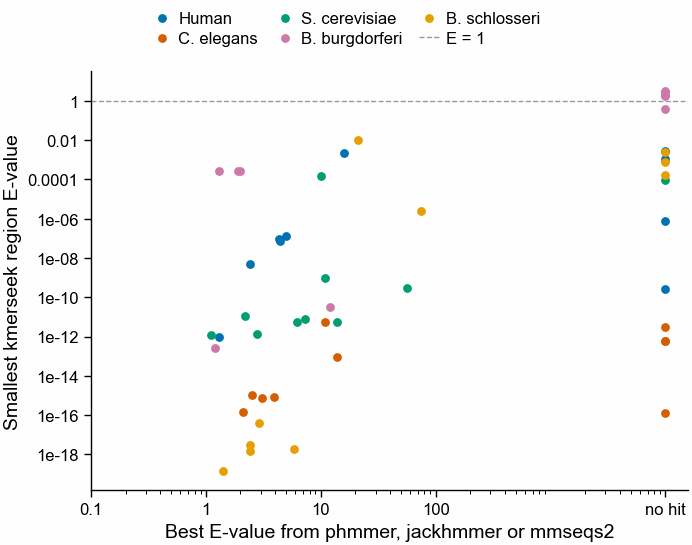

In [7]:
import urllib.parse
import urllib.request

CACHE = Path(
    "/Users/olga/data/invertebrate-dark-set/uniprot_cache/279_example_proteins_repaired_2026_10_23.tsv"
)
accs = sorted(
    set(
        examples.filter(~pl.col("accession").str.starts_with("FUN"))[
            "accession"
        ].to_list()
    )
)
if not CACHE.exists() or set(
    pl.read_csv(CACHE, separator="\t")["Entry"].to_list()
) != set(accs):
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    query = " OR ".join(f"accession:{a}" for a in accs)
    url = "https://rest.uniprot.org/uniprotkb/search?" + urllib.parse.urlencode(
        {
            "query": query,
            "fields": "accession,gene_primary,protein_name,length,ft_compbias,ft_repeat",
            "format": "tsv",
            "size": 500,
        }
    )
    text = urllib.request.urlopen(url, timeout=120).read().decode()
    if not text.startswith("Entry\t"):
        raise ValueError(f"UniProt did not return a table: {text[:200]}")
    CACHE.write_text(text)
uni = pl.read_csv(CACHE, separator="\t", infer_schema_length=0).rename(
    {
        "Entry": "accession",
        "Gene Names (primary)": "gene",
        "Protein names": "protein",
        "Length": "length",
        "Compositional bias": "compbias",
        "Repeat": "repeat",
    }
)
uni = uni.with_columns(
    pl.col("compbias")
    .fill_null("")
    .str.count_matches("COMPBIAS")
    .alias("compbias_stretches"),
    pl.col("repeat").fill_null("").str.count_matches("REPEAT").alias("repeats"),
    pl.col("protein").str.slice(0, 45),
)
print(f"{len(accs)} example accessions, {uni.height} found in UniProt")
ex = examples.join(
    uni.select(
        "accession", "gene", "protein", "length", "compbias_stretches", "repeats"
    ),
    on="accession",
    how="left",
).unique(["species", "accession"], keep="first", maintain_order=True)
print(
    ex.select(
        "species",
        "alphabet",
        "ksize",
        "accession",
        "gene",
        "protein",
        "length",
        "compbias_stretches",
        "repeats",
        "min_region_evalue",
        "best_tool_evalue",
    )
)

NO_HIT = 1e4  # x position for proteins with no tool hit at all
pts = ex.with_columns(pl.col("best_tool_evalue").fill_null(NO_HIT))
SPECIES_COLOUR = dict(
    zip(
        SPECIES,
        [
            pf.OKABE_ITO[c]
            for c in ["blue", "vermillion", "bluish_green", "reddish_purple", "orange"]
        ],
    )
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
for s in SPECIES:
    d = pts.filter(pl.col("species") == s)
    ax.scatter(
        d["best_tool_evalue"],
        d["min_region_evalue"],
        s=10,
        lw=0,
        color=SPECIES_COLOUR[s],
        label=SPECIES_NAME[s],
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1e-1, 1, 10, 100, NO_HIT], ["0.1", "1", "10", "100", "no hit"])
ax.set_xlabel("Best E-value from phmmer, jackhmmer or mmseqs2")
ax.set_ylabel("Smallest kmerseek region E-value")
ax.yaxis.set_major_locator(plt.matplotlib.ticker.LogLocator(base=10, numticks=12))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.axhline(1, color=pf.GREY, lw=0.5, ls="--", label="E = 1")
print(
    pts.group_by("species")
    .agg(
        pl.len().alias("examples"),
        (pl.col("best_tool_evalue") == NO_HIT).sum().alias("no_tool_hit"),
        pl.col("min_region_evalue").min().alias("smallest_kmerseek_evalue"),
    )
    .sort(pl.col("species").replace_strict(order))
)
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / f"279_example_dark_proteins_kmerseek_vs_tool_evalue_scaled{SCALED}")

## 5. Are the dark proteins kmerseek reaches different from the ones it misses?

If kmerseek reaches dark proteins through low-complexity stretches, repeats or
transmembrane helices rather than shared ancestry, the dark proteins it reaches should carry
those features more often than the dark proteins it misses. An H/P alphabet reads a
transmembrane helix as a long run of H, so helices are a likely cause for these alphabets
(notebook 240 held transmembrane segments out of its Pfam test for this reason).

For each species with UniProt accessions and each cutoff, three groups: placed proteins, dark
proteins the best setting of section 3 misses, and dark proteins it reaches. For each group,
the share that UniProt marks with at least one compositional-bias stretch, at least one
repeat, or at least one transmembrane helix. The UniProt annotation of each whole reference
proteome is downloaded once and cached in `/Users/olga/data/invertebrate-dark-set/uniprot_cache/`.

Proteins without a UniProt annotation row (left out of the shares):
┌──────────┬─────────────┬───────────────┬──────────┐
│ species  ┆ tool_cutoff ┆ no_annotation ┆ proteins │
│ ---      ┆ ---         ┆ ---           ┆ ---      │
│ str      ┆ f64         ┆ u32           ┆ u32      │
╞══════════╪═════════════╪═══════════════╪══════════╡
│ human    ┆ 1.0         ┆ 150           ┆ 20600    │
│ worm     ┆ 1.0         ┆ 225           ┆ 19819    │
│ yeast    ┆ 1.0         ┆ 0             ┆ 6049     │
│ borrelia ┆ 1.0         ┆ 0             ┆ 1291     │
│ human    ┆ 10.0        ┆ 150           ┆ 20600    │
│ worm     ┆ 10.0        ┆ 225           ┆ 19819    │
│ yeast    ┆ 10.0        ┆ 0             ┆ 6049     │
│ borrelia ┆ 10.0        ┆ 0             ┆ 1291     │
└──────────┴─────────────┴───────────────┴──────────┘
┌─────────────┬─────────────────┬──────────┬──────────────────────────────┬───────────────┬──────────┬──────────┬────────┬──────────┐
│ tool_cutoff ┆ kmerseek_cutoff ┆ species 

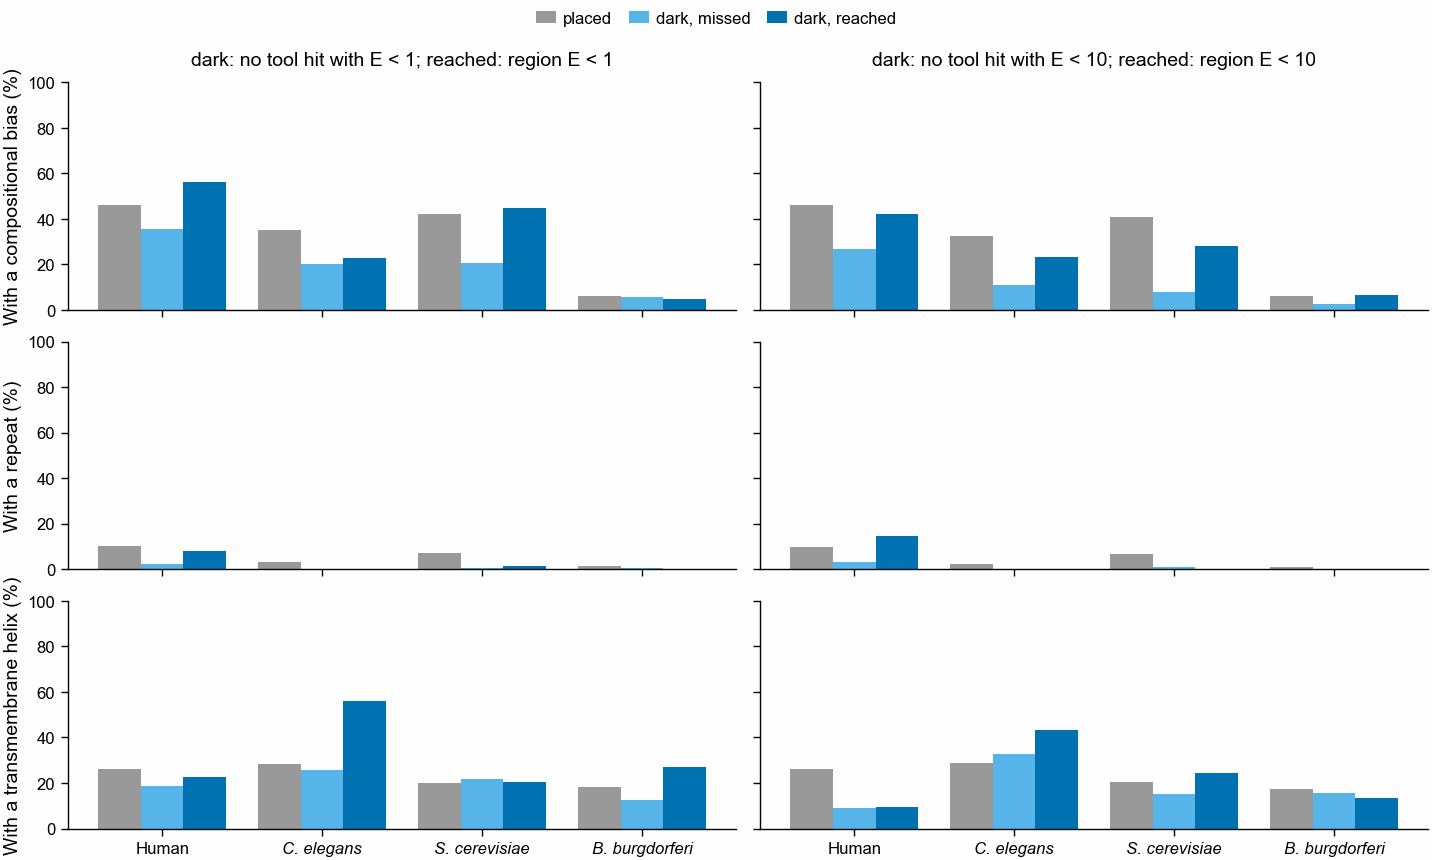

In [8]:
PROTEOMES = {
    "human": "UP000005640",
    "worm": "UP000001940",
    "yeast": "UP000002311",
    "borrelia": "UP000001807",
}
CACHE_DIR = Path("/Users/olga/data/invertebrate-dark-set/uniprot_cache")
FEATURES = {
    "compbias": "compositional bias",
    "repeat": "repeat",
    "transmem": "transmembrane helix",
}
ann = []
for s, up in PROTEOMES.items():
    f = CACHE_DIR / f"{up}_compbias_repeat.tsv"
    if not f.exists():
        url = "https://rest.uniprot.org/uniprotkb/stream?" + urllib.parse.urlencode(
            {
                "query": f"proteome:{up}",
                "fields": "accession,ft_compbias,ft_repeat,ft_transmem",
                "format": "tsv",
            }
        )
        text = urllib.request.urlopen(url, timeout=600).read().decode()
        if not text.startswith("Entry\t"):
            raise ValueError(f"UniProt did not return a table for {up}: {text[:200]}")
        f.write_text(text)
    a = pl.read_csv(f, separator="\t", infer_schema_length=0).rename(
        {
            "Entry": "accession",
            "Compositional bias": "compbias",
            "Repeat": "repeat",
            "Transmembrane": "transmem",
        }
    )
    ann.append(
        a.select(
            "accession",
            *[pl.col(c).is_not_null() & (pl.col(c) != "") for c in FEATURES],
        ).with_columns(pl.lit(s).alias("species"))
    )
ann = pl.concat(ann)

groups = []
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t)
    for r in best.filter(
        (pl.col("tool_cutoff") == t)
        & (pl.col("kmerseek_cutoff") == k)
        & pl.col("species").is_in(list(PROTEOMES))
        & pl.col("alphabet").is_not_null()
    ).iter_rows(named=True):
        reached = set(
            km.filter(
                (pl.col("species") == r["species"])
                & (pl.col("alphabet") == r["alphabet"])
                & (pl.col("ksize") == r["ksize"])
                & (pl.col("scaled") == SCALED)
                & (pl.col("min_region_evalue") < k)
            )["accession"].to_list()
        )
        g = (
            flags.filter(pl.col("species") == r["species"])
            .with_columns(
                pl.when(~pl.col("dark"))
                .then(pl.lit("placed"))
                .when(pl.col("accession").is_in(list(reached)))
                .then(pl.lit("dark, reached"))
                .otherwise(pl.lit("dark, missed"))
                .alias("group")
            )
            .join(ann, on=["species", "accession"], how="left")
        )
        groups.append(
            g.with_columns(
                pl.lit(float(t)).alias("tool_cutoff"),
                pl.lit(float(k)).alias("kmerseek_cutoff"),
                pl.lit(f"{r['alphabet']} k{r['ksize']}").alias("setting"),
            )
        )
groups = pl.concat(groups)
print("Proteins without a UniProt annotation row (left out of the shares):")
print(
    groups.group_by("species", "tool_cutoff")
    .agg(
        pl.col("compbias").is_null().sum().alias("no_annotation"),
        pl.len().alias("proteins"),
    )
    .sort("tool_cutoff", pl.col("species").replace_strict(order))
)
GROUPS = ["placed", "dark, missed", "dark, reached"]
shares = (
    groups.filter(pl.col("compbias").is_not_null())
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", "setting", "group")
    .agg(pl.len().alias("proteins"), *[pl.col(c).mean().alias(c) for c in FEATURES])
    .sort(
        "tool_cutoff",
        pl.col("species").replace_strict(order),
        pl.col("group").replace_strict({g: i for i, g in enumerate(GROUPS)}),
    )
)
print(shares.with_columns(pl.col(list(FEATURES)).round(3)))

GROUP_COLOUR = {
    "placed": pf.GREY,
    "dark, missed": pf.OKABE_ITO["sky_blue"],
    "dark, reached": pf.OKABE_ITO["blue"],
}
sp = [s for s in SPECIES if s in PROTEOMES]
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM,
    110,
    nrows=len(FEATURES),
    ncols=len(CUTOFF_PAIRS),
    sharex=True,
    sharey="row",
    squeeze=False,
)
w = 0.8 / len(GROUPS)
for c, (t, k) in enumerate(CUTOFF_PAIRS):
    for r_i, (feat, feat_name) in enumerate(FEATURES.items()):
        ax = axs[r_i][c]
        for j, g in enumerate(GROUPS):
            d = shares.filter((pl.col("tool_cutoff") == t) & (pl.col("group") == g))
            xs = [sp.index(s) + (j - 1) * w for s in d["species"]]
            ax.bar(xs, 100 * d[feat], width=w, color=GROUP_COLOUR[g], label=g)
        ax.set_ylim(0, 100)
        if c == 0:
            ax.set_ylabel(f"With a {feat_name} (%)")
        if r_i == 0:
            ax.set_title(f"dark: no tool hit with E < {t:g}; reached: region E < {k:g}")
        ax.set_xticks(range(len(sp)), [SPECIES_NAME[s] for s in sp])
        for lab in ax.get_xticklabels():
            lab.set_fontstyle("normal" if lab.get_text() == "Human" else "italic")
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / f"279_dark_reached_vs_missed_uniprot_features_scaled{SCALED}")

## 6. BHF: what phmmer, jackhmmer and kmerseek find on it

BHF (Botryllus histocompatibility factor, FUN008084_FUN008084, 252 residues) is the
project's flagship allorecognition protein. This section draws, on BHF's own residue
positions:

* its low-complexity stretches (SEG first pass) and predicted transmembrane helices
  (Kyte-Doolittle), computed with `notebooks/sequence_masks.py`;
* every hit phmmer and jackhmmer reported for BHF in the run (Swiss-Prot minus Ascidiacea,
  reporting cutoff E = 10). The run stored only target coordinates, so phmmer was run again
  for BHF alone with the same image, reference and cutoff to get the positions on BHF; it
  returned the same seven hits and E-values. jackhmmer reported the same seven hits:
  none passed its inclusion cutoff, so it stopped after its first round, which is phmmer.
  mmseqs2 reported nothing;
* the kmerseek regions on BHF under hp_lehninger2 at k = 17, 19, 21 and 23 (scaled 1, mask
  off, extended at C = 1.51) with E < 10, the cutoff of this notebook, one track per k. k17
  is this alphabet's smallest k in the run (notebook 274's k_min). A region is drawn open
  when at least half of its BHF residues are in a low-complexity stretch.

In the residue printouts, the middle line is the target's H/P encoding (kmerseek's
`moltype_seq`); where the two sequences differ in H/P, the BHF line differs from it.

Inputs: `/Users/olga/data/invertebrate-dark-set/bhf-view/`, made by
`scripts/bhf_view_extract.sh`. kmerseek's own per-query view of the same regions
(`scripts/visualize_hits.py` in the kmerseek repo, top 15 targets by q-value) is
`figures/279_bhf_kmerseek_visualize_hits_hp_lehninger2_k<k>.png`, one per k.
The same regions as an interactive page, one per k:
`figures/279_bhf_kmerseek_search_report_hp_lehninger2_k<k>.html`, made with
`scripts/visualize_search.py` from the branch of kmerseek PR 142 (draft) with
`--min-runs 1 --max-rows 30`, with the seven phmmer hits (the same as jackhmmer's) drawn
on BHF and on each target (`--domains bhf_phmmer_jackhmmer_domains.tsv`). The page marks any target not named `sp|` as
TrEMBL, so it was made from the `.sp.csv` copies, where every target is renamed `sp|ACC|ACC`.

Stored run hits per tool: {'phmmer': 7, 'jackhmmer': 7}
phmmer rerun, stored phmmer and stored jackhmmer report the same targets: True
┌────────┬─────────────────────────────────┬────────┬──────┬───────────┬─────────┐
│ target ┆ target_name                     ┆ evalue ┆ bits ┆ bhf_start ┆ bhf_end │
│ ---    ┆ ---                             ┆ ---    ┆ ---  ┆ ---       ┆ ---     │
│ str    ┆ str                             ┆ f64    ┆ f64  ┆ i64       ┆ i64     │
╞════════╪═════════════════════════════════╪════════╪══════╪═══════════╪═════════╡
│ P27984 ┆ Protein Vpx                     ┆ 0.16   ┆ 16.6 ┆ 137       ┆ 190     │
│ P05918 ┆ Protein Vpx                     ┆ 1.8    ┆ 13.1 ┆ 137       ┆ 181     │
│ Q3IKR2 ┆ Protein GrpE                    ┆ 1.8    ┆ 13.1 ┆ 100       ┆ 181     │
│ P27976 ┆ Protein Vpx                     ┆ 3.1    ┆ 12.3 ┆ 137       ┆ 188     │
│ Q54JA5 ┆ Integrin beta-like protein C    ┆ 4.1    ┆ 11.9 ┆ 108       ┆ 159     │
│ A1AU69 ┆ Ribosomal RNA small subu

Wrote /Users/olga/data/invertebrate-dark-set/bhf-view/viz_k17/FUN008084_FUN008084.hits.png / .svg (15 targets, 16 hits, 11291 regions)


Wrote /Users/olga/data/invertebrate-dark-set/bhf-view/viz_k19/FUN008084_FUN008084.hits.png / .svg (15 targets, 17 hits, 7712 regions)


Wrote /Users/olga/data/invertebrate-dark-set/bhf-view/viz_k21/FUN008084_FUN008084.hits.png / .svg (15 targets, 15 hits, 4771 regions)


Wrote /Users/olga/data/invertebrate-dark-set/bhf-view/viz_k23/FUN008084_FUN008084.hits.png / .svg (15 targets, 15 hits, 1631 regions)


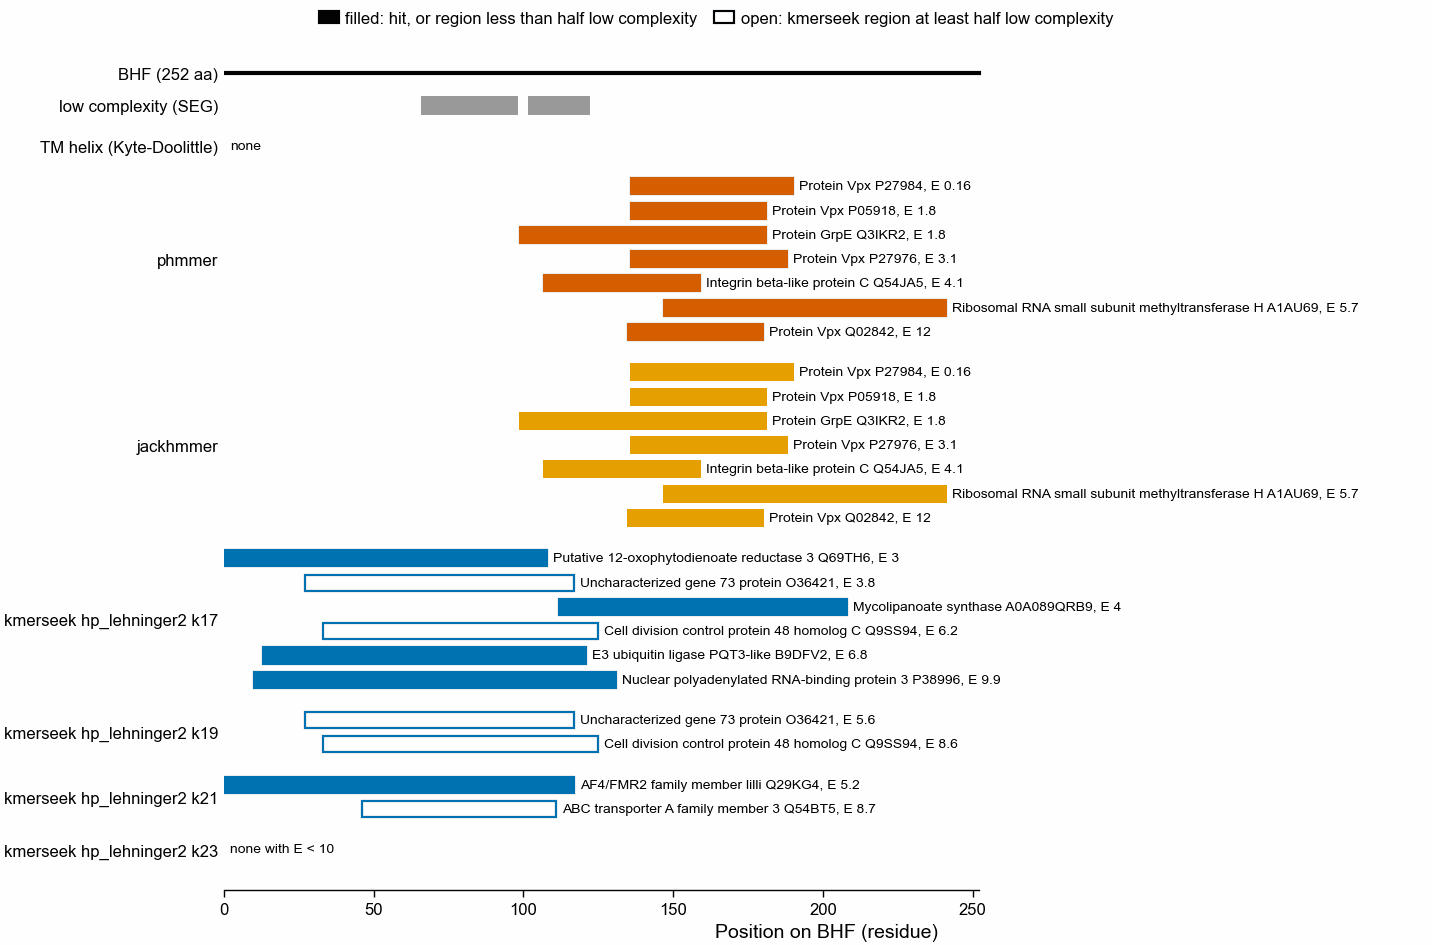

In [9]:
import re
import shutil
import subprocess

import sequence_masks as sm

BHF = Path("/Users/olga/data/invertebrate-dark-set/bhf-view")
BHF_ID = "FUN008084_FUN008084"
bhf_seq = "".join(l.strip() for l in open(BHF / "bhf.fasta") if not l.startswith(">"))
names = dict(pl.read_csv(BHF / "target_names.tsv", separator="\t").iter_rows())

# Every phmmer domain hit on BHF: positions on BHF (hmm from/to) and on the target
dom = []
for line in open(BHF / "bhf_phmmer.domtbl"):
    if line.startswith("#"):
        continue
    f = line.split()
    dom.append(
        {
            "target": f[0],
            "evalue": float(f[12]),
            "bits": float(f[13]),
            "bhf_start": int(f[15]),
            "bhf_end": int(f[16]),
            "target_start": int(f[17]),
            "target_end": int(f[18]),
        }
    )
dom = (
    pl.DataFrame(dom)
    .with_columns(
        pl.col("target").replace_strict(names, default="").alias("target_name")
    )
    .sort("evalue")
)
stored = pl.read_csv(
    BHF / "bhf_tool_hits.tsv",
    separator="\t",
    has_header=False,
    new_columns=["tool", "query", "target", "tstart", "tend", "bits", "evalue"],
)
print("Stored run hits per tool:", dict(stored.group_by("tool").len().iter_rows()))
same = (
    set(stored.filter(pl.col("tool") == "phmmer")["target"])
    == set(dom["target"])
    == set(stored.filter(pl.col("tool") == "jackhmmer")["target"])
)
print("phmmer rerun, stored phmmer and stored jackhmmer report the same targets:", same)
print(dom.select("target", "target_name", "evalue", "bits", "bhf_start", "bhf_end"))

# kmerseek regions on BHF, hp_lehninger2 at each k
BHF_KS = [17, 19, 21, 23]
kr = pl.concat(
    [
        pl.read_csv(
            BHF / f"bhf_hp_lehninger2_k{k}_s1.csv", infer_schema_length=0
        ).with_columns(pl.lit(k).alias("k"))
        for k in BHF_KS
    ]
).with_columns(
    pl.col("region_start", "region_end", "target_start", "target_end").cast(pl.Int64),
    pl.col("region_evalue").cast(pl.Float64),
)
lc = sm.low_complexity_mask(bhf_seq)
tm = sm.helix_mask(bhf_seq)
kr = kr.with_columns(
    pl.struct("region_start", "region_end")
    .map_elements(
        lambda r: sum(lc[r["region_start"] : r["region_end"]])
        / (r["region_end"] - r["region_start"]),
        return_dtype=pl.Float64,
    )
    .alias("bhf_lc_share")
)
print(
    kr.group_by("k")
    .agg(
        pl.len().alias("regions"),
        (pl.col("region_evalue") < 10).sum().alias("E_below_10"),
        (pl.col("region_evalue") < 1).sum().alias("E_below_1"),
        pl.col("region_evalue").min().alias("smallest_E"),
    )
    .sort("k")
)

# Names of the targets with E < 10: the run's Swiss-Prot names, then UniProt for any missing (cached)
kshow = kr.filter(pl.col("region_evalue") < 10).sort("k", "region_evalue")
missing = sorted(set(kshow["target_name"]) - set(names))
NAME_CACHE = BHF / "target_names_uniprot.tsv"
if missing and (
    not NAME_CACHE.exists()
    or set(missing) - set(pl.read_csv(NAME_CACHE, separator="\t")["Entry"])
):
    url = "https://rest.uniprot.org/uniprotkb/search?" + urllib.parse.urlencode(
        {
            "query": " OR ".join(f"accession:{a}" for a in missing),
            "fields": "accession,protein_name",
            "format": "tsv",
            "size": 500,
        }
    )
    text = urllib.request.urlopen(url, timeout=120).read().decode()
    if not text.startswith("Entry\t"):
        raise ValueError(f"UniProt did not return a table: {text[:200]}")
    NAME_CACHE.write_text(text)
if NAME_CACHE.exists():
    names.update(
        dict(
            pl.read_csv(NAME_CACHE, separator="\t")
            .select("Entry", "Protein names")
            .iter_rows()
        )
    )
kshow = kshow.with_columns(
    pl.col("target_name").replace_strict(names, default="").alias("target_description")
)
print(
    kshow.select(
        "k",
        "target_name",
        "target_description",
        "region_start",
        "region_end",
        "region_evalue",
        pl.col("bhf_lc_share").round(2),
    )
)
print("BHF low-complexity stretches (0-based, end-exclusive):", sm.stretches(lc))
print("BHF predicted transmembrane helices:", sm.stretches(tm) or "none")

# Residues: phmmer's best hit, from its alignment, and kmerseek's best region at each k
phmmer_text = open(BHF / "bhf_phmmer.out").read()
best_phmmer = dom["target"][0]
block = (
    phmmer_text.split(f">> {best_phmmer}")[1]
    .split("== domain 1")[1]
    .split(">>")[0]
    .splitlines()
)
aln = [l for l in block[1:5] if l.strip()]
print(
    f"\nphmmer, best hit {best_phmmer} ({names.get(best_phmmer, '')}), E = {dom['evalue'][0]:g}:"
)
print("\n".join(aln[:3]))
for b in (
    kshow.sort("region_evalue")
    .unique("k", keep="first")
    .sort("k")
    .iter_rows(named=True)
):
    print(
        f"\nkmerseek hp_lehninger2 k{b['k']}, best region on BHF, target {b['target_name']} ({b['target_description']}), E = {b['region_evalue']:.3g}:"
    )
    for lab, seq in [
        (f"BHF {b['region_start'] + 1}-{b['region_end']}", b["region_subseq"]),
        ("target H/P", b["moltype_seq"]),
        (
            f"{b['target_name']} {b['target_start'] + 1}-{b['target_end']}",
            b["target_subseq"],
        ),
    ]:
        for i in range(0, len(seq), 60):
            print(f"{lab if i == 0 else '':>20}  {seq[i:i + 60]}")

# kmerseek's own view at each k, made with the kmerseek repo's script, unchanged
viz = Path("/Users/olga/code/kmerseek/scripts/visualize_hits.py")
for k in BHF_KS:
    viz_out = BHF / f"viz_k{k}"
    subprocess.run(
        [
            sys.executable,
            str(viz),
            "--csv",
            str(BHF / f"bhf_hp_lehninger2_k{k}_s1.csv"),
            "--query-fasta",
            str(BHF / "bhf.fasta"),
            "--output-dir",
            str(viz_out),
            "--max-hits",
            "15",
        ],
        check=True,
    )
    shutil.copy(
        viz_out / f"{BHF_ID}.hits.png",
        FIG / f"279_bhf_kmerseek_visualize_hits_hp_lehninger2_k{k}.png",
    )

# The tracks figure
TRACK_COLOUR = {
    "phmmer": pf.OKABE_ITO["vermillion"],
    "jackhmmer": pf.OKABE_ITO["orange"],
}
TRACK_COLOUR.update({f"kmerseek k{k}": pf.OKABE_ITO["blue"] for k in BHF_KS})


def lanes(spans):
    # Stack overlapping (start, end) spans into lanes; returns a lane index per span
    ends, out = [], []
    for s, e in spans:
        for i, last in enumerate(ends):
            if s >= last + 2:
                ends[i] = e
                out.append(i)
                break
        else:
            ends.append(e)
            out.append(len(ends) - 1)
    return out


rows = []  # (track, start, end, label, filled)
for s_, e_ in sm.stretches(lc):
    rows.append(("low complexity", s_, e_, "", True))
for s_, e_ in sm.stretches(tm):
    rows.append(("transmembrane helix", s_, e_, "", True))
for tool_name in ["phmmer", "jackhmmer"]:
    for r in dom.iter_rows(named=True):
        rows.append(
            (
                tool_name,
                r["bhf_start"] - 1,
                r["bhf_end"],
                f"{r['target_name'].split(' (')[0]} {r['target']}, E {r['evalue']:g}",
                True,
            )
        )
for r in kshow.iter_rows(named=True):
    rows.append(
        (
            f"kmerseek k{r['k']}",
            r["region_start"],
            r["region_end"],
            f"{(r['target_description'] or '?').split(' (')[0]} {r['target_name']}, E {r['region_evalue']:.2g}",
            r["bhf_lc_share"] < 0.5,
        )
    )
TRACKS = ["low complexity", "transmembrane helix", "phmmer", "jackhmmer"] + [
    f"kmerseek k{k}" for k in BHF_KS
]
LABEL = {
    "low complexity": "low complexity (SEG)",
    "transmembrane helix": "TM helix (Kyte-Doolittle)",
}
LABEL.update({f"kmerseek k{k}": f"kmerseek hp_lehninger2 k{k}" for k in BHF_KS})
n_rows = (
    sum(
        max(1, len([r for r in rows if r[0] == t]))
        for t in TRACKS
        if not t.startswith(("low", "trans"))
    )
    + 3
)
y = 0.0
yticks, ylabels = [], []
fig, ax = pf.figure(pf.TWO_COLUMN_MM, min(170, 20 + 3.6 * n_rows))
L = len(bhf_seq)
ax.plot([0, L], [y, y], color="black", lw=1.5)
yticks.append(y)
ylabels.append(f"BHF ({L} aa)")
y -= 1.2
for t in TRACKS:
    sub = [r for r in rows if r[0] == t]
    # One row per hit (the low-complexity stretches share one row), so no label runs into a box
    ln = (
        lanes([(r[1], r[2]) for r in sub])
        if t in ("low complexity", "transmembrane helix")
        else list(range(len(sub)))
    )
    n = max(ln) + 1 if ln else 1
    yticks.append(y - (n - 1) / 2 * 0.9)
    ylabels.append(LABEL.get(t, t))
    if not sub:
        ax.text(
            2,
            y,
            "none with E < 10" if t.startswith("kmerseek") else "none",
            va="center",
            fontsize=5,
        )
    for r, li in zip(sub, ln):
        yy = y - li * 0.9
        colour = TRACK_COLOUR.get(t, pf.GREY)
        ax.add_patch(
            plt.Rectangle(
                (r[1], yy - 0.3),
                r[2] - r[1],
                0.6,
                facecolor=colour if r[4] else "white",
                edgecolor=colour,
                lw=0.8,
            )
        )
        if r[3]:
            ax.text(r[2] + 2, yy, r[3], va="center", fontsize=5)
    y -= n * 0.9 + 0.6
ax.set_xlim(0, L + 150)
ax.set_ylim(y, 0.8)
ax.set_yticks(yticks, ylabels)
ax.set_xticks(range(0, L + 1, 50))
ax.set_xlabel("Position on BHF (residue)")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.spines["bottom"].set_bounds(0, L)
for lab, kw in [
    (
        "filled: hit, or region less than half low complexity",
        dict(facecolor="black", edgecolor="black"),
    ),
    (
        "open: kmerseek region at least half low complexity",
        dict(facecolor="white", edgecolor="black"),
    ),
]:
    ax.add_patch(plt.Rectangle((0, 0), 0, 0, label=lab, lw=0.8, **kw))
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / "279_bhf_phmmer_jackhmmer_kmerseek_hp_lehninger2_k17_k23")

### 6b. Does BHF share more H/P k-mers than shuffled BHF at k below 17?

hp_lehninger2's smallest k in the run is 17. Before building indexes at smaller k for one
protein, a cheaper count: `scripts/bhf_hp_seed_null.py` writes BHF and every protein of the
run's reference (Swiss-Prot minus Ascidiacea) in hp_lehninger2 (`AFGILMPVWY` hydrophobic,
h; `CDEHKNQRST` polar, p) and counts, at k = 11 to 16, the reference proteins that share
exact H/P k-mers with BHF. Shared means the same k-mer anywhere in both proteins, not on one
diagonal: these are seeds, not regions, and they have no E-value. The same count is made for
100 copies of BHF with its residues shuffled one at a time (same residue counts, new order;
seed 0).

Two numbers per k:

* **(a)** how many reference proteins share at least 2 distinct k-mers with the query;
* **(b)** the most distinct k-mers the query shares with any one protein.

A homolog shows up as one protein sharing many k-mers, so smaller-k indexes are worth
building for BHF only if BHF beats the copies on (b). (a) can rise when many proteins each
share a few k-mers with one repeated stretch. Higher than the copies means BHF's residue
order matters; p = (1 + copies at or above BHF) / 101.

BHF against 100 shuffled copies, exact hp_lehninger2 k-mers shared with Swiss-Prot minus Ascidiacea
┌─────┬─────────────────────────────────┬────────┬───────────────┬────────────────┬─────────────────┬───────────────────┬───────┐
│ k   ┆ measure                         ┆ BHF    ┆ copies_median ┆ copies_5th_pct ┆ copies_95th_pct ┆ BHF_vs_median_pct ┆ p     │
│ --- ┆ ---                             ┆ ---    ┆ ---           ┆ ---            ┆ ---             ┆ ---               ┆ ---   │
│ i64 ┆ str                             ┆ i64    ┆ f64           ┆ f64            ┆ f64             ┆ f64               ┆ f64   │
╞═════╪═════════════════════════════════╪════════╪═══════════════╪════════════════╪═════════════════╪═══════════════════╪═══════╡
│ 11  ┆ (a) proteins sharing at least … ┆ 558126 ┆ 557902.0      ┆ 555955.0       ┆ 559716.0        ┆ 0.0               ┆ 0.406 │
│ 11  ┆ (b) most k-mers shared with on… ┆ 218    ┆ 220.0         ┆ 207.0          ┆ 228.0           ┆ -0.9              

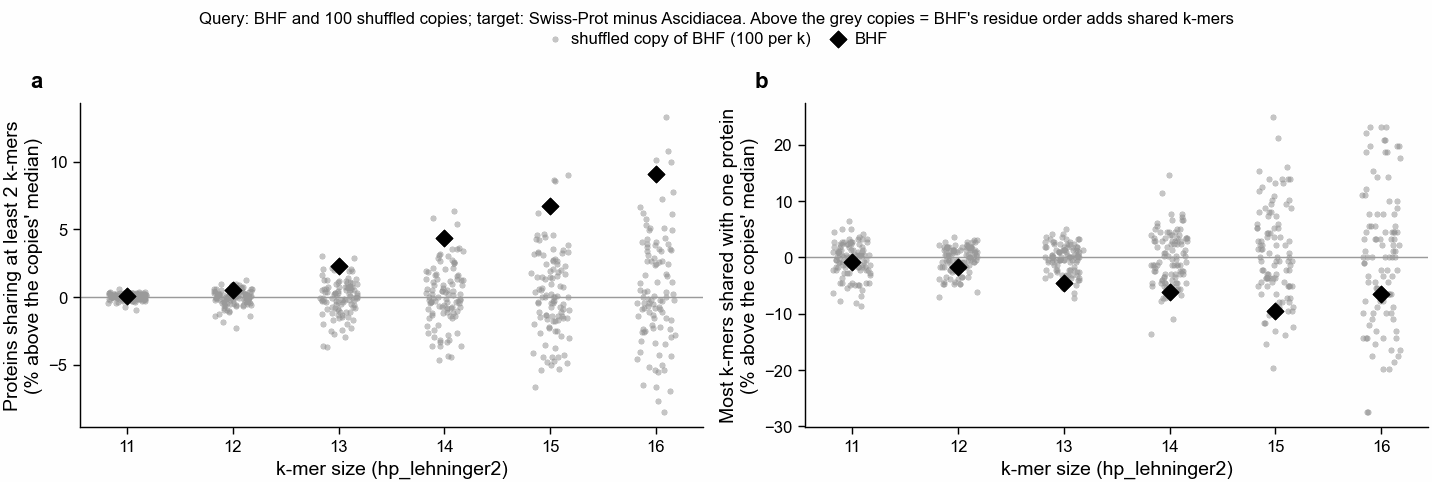

In [10]:
import numpy as np

seed = pl.read_csv(BHF / "bhf_hp_lehninger2_seed_null.counts.tsv", separator="\t")
seed_top = pl.read_csv(BHF / "bhf_hp_lehninger2_seed_null.bhf_top.tsv", separator="\t")
SEED_KS = sorted(seed["k"].unique())
assert all(
    seed.filter(pl.col("k") == k).height == 101 for k in SEED_KS
), "expected BHF + 100 copies per k"
SEED_MEASURES = {
    "proteins_ge2": "(a) proteins sharing at least 2 k-mers",
    "max_shared": "(b) most k-mers shared with one protein",
}
rows = []
for k in SEED_KS:
    sub = seed.filter(pl.col("k") == k)
    b = sub.filter(pl.col("query") == "BHF").row(0, named=True)
    sh = sub.filter(pl.col("query") != "BHF")
    for m, label in SEED_MEASURES.items():
        rows.append(
            {
                "k": k,
                "measure": label,
                "BHF": b[m],
                "copies_median": sh[m].median(),
                "copies_5th_pct": sh[m].quantile(0.05, "nearest"),
                "copies_95th_pct": sh[m].quantile(0.95, "nearest"),
                "BHF_vs_median_pct": round(100 * (b[m] / sh[m].median() - 1), 1),
                "p": round((1 + (sh[m] >= b[m]).sum()) / (1 + sh.height), 3),
            }
        )
seed_tab = pl.DataFrame(rows)
print(
    "BHF against 100 shuffled copies, exact hp_lehninger2 k-mers shared with Swiss-Prot minus Ascidiacea"
)
print(seed_tab)
seed_tab.write_csv(
    TABLES / "279_bhf_hp_lehninger2_seed_counts_vs_shuffles_swissprot.csv"
)

# The proteins BHF shares the most k-mers with, k 13-16 (names from the UniProt cache below, where present)
feat_tsv = pl.read_csv(
    BHF / "target_uniprot_features.tsv", separator="\t", infer_schema_length=0
).fill_null("")
uniprot_name = dict(feat_tsv.select("Entry", "Protein names").iter_rows())
print("\nProteins sharing the most k-mers with BHF (k 13-16), three per k:")
print(
    seed_top.filter(pl.col("k") >= 13)
    .group_by("k", maintain_order=True)
    .head(3)
    .with_columns(
        pl.col("target")
        .replace_strict(uniprot_name, default="")
        .str.slice(0, 50)
        .alias("name")
    )
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=2)
rng = np.random.default_rng(0)
for ax, (m, label) in zip(axs, SEED_MEASURES.items()):
    for k in SEED_KS:
        sub = seed.filter(pl.col("k") == k)
        sh = sub.filter(pl.col("query") != "BHF")[m].to_numpy()
        med = np.median(sh)
        b = sub.filter(pl.col("query") == "BHF")[m][0]
        ax.scatter(
            k + rng.uniform(-0.18, 0.18, len(sh)),
            100 * (sh / med - 1),
            s=5,
            color=pf.GREY,
            alpha=0.6,
            lw=0,
            label="shuffled copy of BHF (100 per k)" if k == SEED_KS[0] else None,
        )
        ax.scatter(
            [k],
            [100 * (b / med - 1)],
            marker="D",
            s=18,
            color="black",
            zorder=3,
            label="BHF" if k == SEED_KS[0] else None,
        )
    ax.axhline(0, color=pf.GREY, lw=0.5, zorder=0)
    ax.set_xticks(SEED_KS)
    ax.set_xlabel("k-mer size (hp_lehninger2)")
    ax.set_ylabel(label[4:].capitalize() + "\n(% above the copies' median)")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "Query: BHF and 100 shuffled copies; target: Swiss-Prot minus Ascidiacea. "
        "Above the grey copies = BHF's residue order adds shared k-mers"
    ),
    title_fontsize=6,
)
pf.save(fig, FIG / "279_bhf_hp_lehninger2_seed_counts_vs_shuffles_k11_k16_swissprot")

### 6c. Do BHF's regions survive a low-complexity filter, and do they beat shuffled BHF?

BHF has two low-complexity stretches (SEG first pass, as in section 6): residues 67-98 and
103-122 (1-based), the lysine-rich part of the protein. A region whose evidence comes from
there is a composition match, not a homolog. Three ways to call a region low complexity:

* **share of the region**: at least half of the region's BHF residues lie in a stretch (the
  rule of sections 6 and 7). Extended regions are often 100 residues long, so a region can
  pass this rule while all its shared k-mers sit inside a stretch, or fail it while none do;
* **share of the shared k-mers**: at least half of the BHF residues covered by the region's
  exact shared H/P k-mers lie in a stretch. A region of one piece is gapless, so the k-mers are found by
  comparing BHF's H/P string with the target's position by position (a region chained from
  two pieces is matched within the run's chain shift of 10). The number found equals
  kmerseek's `region_n_shared_kmers` for every region (checked below);
* **share of the shared k-mers, on both proteins**: as the rule before, and also at least
  half of the target residues under those k-mers lie in a low-complexity stretch of the
  target's region (SEG on the target's region residues only, since the run stored no whole
  target). A run of BHF's ordinary residues can share its H/P pattern with a target's
  glutamate run, and only this rule sees that. A region is kept only if it passes both sides.

**Chance control.** 100 copies of BHF, each with its residues shuffled so that every
adjacent residue pair keeps its count (a dipeptide shuffle, Altschul and Erickson 1985, as
in notebook 256; `data/279_bhf_dipeptide_shuffles.fasta`, seed 279). This keeps lysine runs
together only in part: the copies have fewer low-complexity residues than BHF (printed
below), so the rules remove less from them. Each copy gets its own SEG mask. The copies were searched together with BHF's own 2_000-protein query chunk
against the run's hp_lehninger2 indexes, with the run's image and flags
(`scripts/279_bhf_shuffle_search.sbatch`, Slurm jobs 47649404, 47649408, 47649416 and
47649421, 2026-10-13). BHF's own regions in that search must equal the run's (checked below).

**Decision, written before the copies' results were read.** The rule that decides is the
last one (shared k-mers outside low complexity on both proteins); the others are shown to
see what each filter removes. At a k, BHF has a candidate only if, under that rule, its
best region E-value is smaller than that of at least 95 of the 100 copies:
p = (1 + copies with a best E-value at or below BHF's) / 101 <= 0.05. Lower E is better; a
copy with no region below E = 10 counts as worse than BHF. Four k-sizes are tested, so one
p near 0.05 among them is expected by chance.

Low-complexity residues per query: BHF 52 ; copies median 15 range 0 - 58


Queries with any region in the shuffle search: [(17, 101), (19, 101), (21, 101), (23, 101)]
k17: BHF regions in the run 11_291, in the shuffle search 11_291, identical: True
k19: BHF regions in the run 7_712, in the shuffle search 7_712, identical: True
k21: BHF regions in the run 4_771, in the shuffle search 4_771, identical: True
k23: BHF regions in the run 1_631, in the shuffle search 1_631, identical: True


Shared k-mers found = region_n_shared_kmers in all 1104 regions with E < 10
┌─────┬──────────────────────────────┬────────────────────────┬────────────┬─────────────────────────────────┬───────────────────────┬──────────────────────┬───────────────────────────────┬───────┐
│ k   ┆ rule                         ┆ BHF_regions_E_below_10 ┆ BHF_best_E ┆ copies_with_a_region_E_below_1… ┆ copies_best_E_below_1 ┆ copies_best_E_median ┆ copies_at_or_below_BHF_best_E ┆ p     │
│ --- ┆ ---                          ┆ ---                    ┆ ---        ┆ ---                             ┆ ---                   ┆ ---                  ┆ ---                           ┆ ---   │
│ i64 ┆ str                          ┆ i64                    ┆ f64        ┆ i64                             ┆ i64                   ┆ f64                  ┆ i64                           ┆ f64   │
╞═════╪══════════════════════════════╪════════════════════════╪════════════╪═════════════════════════════════╪══════════════════════

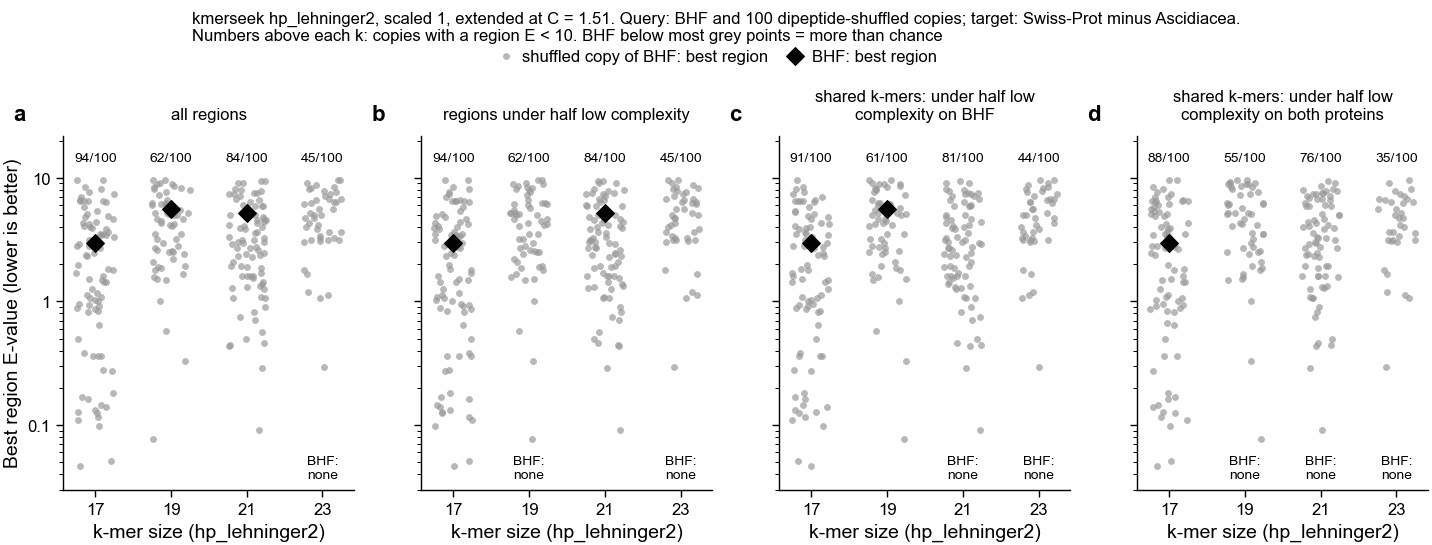

In [11]:
import io
from collections import Counter

HP_H = set("AFGILMPVWY")  # hp_lehninger2 hydrophobic; the other 10 residues are polar


def to_hp(s):
    return "".join("h" if c in HP_H else "p" for c in s)


def read_fasta(path):
    out, name = {}, None
    for line in open(path):
        if line.startswith(">"):
            name = line[1:].split()[0]
            out[name] = ""
        else:
            out[name] += line.strip()
    return out


copies = read_fasta(Path("../data/279_bhf_dipeptide_shuffles.fasta"))
pairs = lambda s: Counter(s[i : i + 2] for i in range(len(s) - 1))
assert len(copies) == 100 and all(
    pairs(s) == pairs(bhf_seq) and s != bhf_seq for s in copies.values()
)
query_seq = {BHF_ID: bhf_seq, **copies}
query_lc = {q: sm.low_complexity_mask(s) for q, s in query_seq.items()}
print(
    "Low-complexity residues per query: BHF",
    sum(query_lc[BHF_ID]),
    "; copies median",
    int(np.median([sum(query_lc[q]) for q in copies])),
    "range",
    min(sum(query_lc[q]) for q in copies),
    "-",
    max(sum(query_lc[q]) for q in copies),
)


CHAIN_MAX_SHIFT = 10  # the run's --chain-max-shift


def seed_offsets(r, encode=None):
    # (offset on BHF's region, offset on the target's region) of each exact shared H/P k-mer, and
    # the offsets of every BHF and every target residue they cover. A region of one piece
    # (region_n_chained = 1) is gapless, so a k-mer sits on the same offset in both. A chained
    # region joins pieces whose diagonals differ by up to CHAIN_MAX_SHIFT, so its k-mers are
    # matched within that shift. `encode` writes BHF's residues in the region's alphabet
    # (hp_lehninger2 when not given).
    q, t, k = (encode or to_hp)(r["region_subseq"]), r["moltype_seq"], r["k"]
    if r["region_n_chained"] == 1:
        assert len(q) == len(t)
        pairs = [(i, i) for i in range(len(q) - k + 1) if q[i : i + k] == t[i : i + k]]
    else:
        at = {}
        for j in range(len(t) - k + 1):
            at.setdefault(t[j : j + k], []).append(j)
        pairs = []
        for i in range(len(q) - k + 1):
            near = [
                j for j in at.get(q[i : i + k], []) if abs(j - i) <= CHAIN_MAX_SHIFT
            ]
            if near:
                pairs.append((i, min(near, key=lambda j: abs(j - i))))
    return (
        pairs,
        sorted({i + d for i, _ in pairs for d in range(k)}),
        sorted({j + d for _, j in pairs for d in range(k)}),
    )


def annotate(df):
    extra = []
    for r in df.iter_rows(named=True):
        s0, e0, mask = r["region_start"], r["region_end"], query_lc[r["query_name"]]
        assert query_seq[r["query_name"]][s0:e0] == r["region_subseq"]
        pairs, qcols, tcols = seed_offsets(r)
        tmask = sm.low_complexity_mask(r["target_subseq"])
        extra.append(
            {
                "n_seeds_found": len(pairs),
                "region_lc_share": sum(mask[s0:e0]) / (e0 - s0),
                "seed_lc_share": sum(mask[s0 + j] for j in qcols) / len(qcols),
                "target_seed_lc_share": sum(tmask[j] for j in tcols) / len(tcols),
                # residue by residue only where the two strings line up (one piece)
                "identical_residues": (
                    sum(a == b for a, b in zip(r["region_subseq"], r["target_subseq"]))
                    if r["region_n_chained"] == 1
                    else None
                ),
            }
        )
    return pl.concat([df, pl.DataFrame(extra)], how="horizontal")


# The shuffle search, copied from $SCRATCH/279-bhf-shuffle on Sherlock
SHUF = BHF / "shuffle"
COLS = [
    "query_name",
    "target_name",
    "region_start",
    "region_end",
    "region_subseq",
    "target_start",
    "target_end",
    "target_subseq",
    "moltype_seq",
    "region_n_shared_kmers",
    "region_n_chained",
    "region_evalue",
]
sr = []
for k in BHF_KS:
    raw = subprocess.run(
        [
            "zstd",
            "-dc",
            str(
                SHUF
                / f"bhf_shuffles.hp_lehninger2.k{k}.s1.lcfalse.extend-c1.51.regions.csv.zst"
            ),
        ],
        check=True,
        capture_output=True,
    ).stdout
    sr.append(
        pl.read_csv(io.BytesIO(raw), columns=COLS, infer_schema_length=0).with_columns(
            pl.lit(k).alias("k")
        )
    )
sr = pl.concat(sr).with_columns(
    pl.col(
        "region_start",
        "region_end",
        "target_start",
        "target_end",
        "region_n_shared_kmers",
        "region_n_chained",
    ).cast(pl.Int64),
    pl.col("region_evalue").cast(pl.Float64),
)
print(
    "Queries with any region in the shuffle search:",
    sr.group_by("k").agg(pl.col("query_name").n_unique()).sort("k").rows(),
)

# BHF's regions in this search must be the run's regions
KEY = [
    "target_name",
    "region_start",
    "region_end",
    "target_start",
    "target_end",
    "region_evalue",
]
for k in BHF_KS:
    a = kr.filter(pl.col("k") == k).select(KEY).sort(KEY)
    b = (
        sr.filter((pl.col("k") == k) & (pl.col("query_name") == BHF_ID))
        .select(KEY)
        .sort(KEY)
    )
    print(
        f"k{k}: BHF regions in the run {a.height:_}, in the shuffle search {b.height:_}, identical: {a.equals(b)}"
    )
    assert a.equals(b)

RULES = [
    "no filter",
    "share of the region",
    "share of the shared k-mers",
    "shared k-mers, both proteins",
]
ann = annotate(sr.filter(pl.col("region_evalue") < 10))
assert (
    ann["n_seeds_found"] == ann["region_n_shared_kmers"]
).all(), "seed count differs from kmerseek's"
print(
    f"Shared k-mers found = region_n_shared_kmers in all {ann.height} regions with E < 10"
)
ann = ann.with_columns(
    pl.lit(True).alias("no filter"),
    (pl.col("region_lc_share") < 0.5).alias("share of the region"),
    (pl.col("seed_lc_share") < 0.5).alias("share of the shared k-mers"),
    ((pl.col("seed_lc_share") < 0.5) & (pl.col("target_seed_lc_share") < 0.5)).alias(
        "shared k-mers, both proteins"
    ),
)

# Best E-value and number of regions with E < 10, per query, k and rule (no region = null best, 0 regions)
bhf_grid = (
    pl.DataFrame({"query_name": list(query_seq)})
    .join(pl.DataFrame({"k": BHF_KS}), how="cross")
    .join(pl.DataFrame({"rule": RULES}), how="cross")
)
bhf_per = pl.concat(
    [
        ann.filter(pl.col(rule))
        .group_by("query_name", "k")
        .agg(
            pl.col("region_evalue").min().alias("best_E"),
            pl.len().alias("n_E_below_10"),
        )
        .with_columns(pl.lit(rule).alias("rule"))
        for rule in RULES
    ]
)
bhf_per = bhf_grid.join(
    bhf_per, on=["query_name", "k", "rule"], how="left"
).with_columns(pl.col("n_E_below_10").fill_null(0))
rows = []
for (k, rule), g in bhf_per.group_by("k", "rule", maintain_order=True):
    b = g.filter(pl.col("query_name") == BHF_ID).row(0, named=True)
    c = g.filter(pl.col("query_name") != BHF_ID)
    as_good = None if b["best_E"] is None else int((c["best_E"] <= b["best_E"]).sum())
    rows.append(
        {
            "k": k,
            "rule": rule,
            "BHF_regions_E_below_10": b["n_E_below_10"],
            "BHF_best_E": b["best_E"],
            "copies_with_a_region_E_below_10": int(c["best_E"].is_not_null().sum()),
            "copies_best_E_below_1": int((c["best_E"] < 1).sum()),
            "copies_best_E_median": c["best_E"].median(),
            "copies_at_or_below_BHF_best_E": as_good,
            "p": None if as_good is None else round((1 + as_good) / 101, 3),
        }
    )
lc_tab = pl.DataFrame(rows).sort(
    "k", pl.col("rule").replace_strict({r: i for i, r in enumerate(RULES)})
)
print(lc_tab)
lc_tab.write_csv(
    TABLES
    / "279_bhf_regions_low_complexity_vs_dipeptide_shuffles_hp_lehninger2_swissprot.csv"
)

bhf_ann = ann.filter(pl.col("query_name") == BHF_ID).with_columns(
    pl.col("target_name")
    .replace_strict(uniprot_name, default="")
    .str.slice(0, 45)
    .alias("target_description")
)
print("\nBHF's regions with E < 10, each rule (True = kept):")
print(
    bhf_ann.sort("k", "region_evalue").select(
        "k",
        "target_name",
        "target_description",
        "region_start",
        "region_end",
        pl.col("region_evalue").round(2),
        "region_n_shared_kmers",
        pl.col("region_lc_share").round(2),
        pl.col("seed_lc_share").round(2),
        pl.col("target_seed_lc_share").round(2),
        "identical_residues",
        *RULES[1:],
    )
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 70, ncols=4, sharey=True)
for ax, rule in zip(axs, RULES):
    for k in BHF_KS:
        g = bhf_per.filter((pl.col("k") == k) & (pl.col("rule") == rule))
        c = g.filter((pl.col("query_name") != BHF_ID) & pl.col("best_E").is_not_null())[
            "best_E"
        ].to_numpy()
        ax.scatter(
            k + rng.uniform(-0.5, 0.5, len(c)),
            c,
            s=6,
            color=pf.GREY,
            alpha=0.7,
            lw=0,
            label="shuffled copy of BHF: best region" if k == BHF_KS[0] else None,
        )
        b = g.filter(pl.col("query_name") == BHF_ID)["best_E"][0]
        if b is not None:
            ax.scatter(
                [k],
                [b],
                marker="D",
                s=20,
                color="black",
                zorder=3,
                label="BHF: best region" if k == BHF_KS[0] else None,
            )
        else:
            ax.text(k, 0.035, "BHF:\nnone", ha="center", va="bottom", fontsize=5)
        ax.text(k, 13, f"{len(c)}/100", ha="center", va="bottom", fontsize=5)
    ax.set_yscale("log")
    ax.set_ylim(0.03, 22)
    ax.set_yticks([0.1, 1, 10], ["0.1", "1", "10"])
    ax.set_xticks(BHF_KS)
    ax.set_xlabel("k-mer size (hp_lehninger2)")
    ax.set_title(
        {
            "no filter": "all regions",
            "share of the region": "regions under half low complexity",
            "share of the shared k-mers": "shared k-mers: under half low\ncomplexity on BHF",
            "shared k-mers, both proteins": "shared k-mers: under half low\ncomplexity on both proteins",
        }[rule],
        fontsize=6,
    )
axs[0].set_ylabel("Best region E-value (lower is better)")
for ax, letter in zip(axs, "abcd"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "kmerseek hp_lehninger2, scaled 1, extended at C = 1.51. Query: BHF and 100 dipeptide-shuffled copies; "
        "target: Swiss-Prot minus Ascidiacea.\nNumbers above each k: copies with a region E < 10. "
        "BHF below most grey points = more than chance"
    ),
    title_fontsize=6,
)
pf.save(
    fig,
    FIG
    / "279_bhf_best_region_evalue_vs_dipeptide_shuffles_low_complexity_rules_hp_lehninger2_swissprot",
)

### 6d. Do BHF's regions land on a zinc finger, a membrane anchor or a DNA-binding region?

For every target of BHF's regions (15_207 proteins over k17-k23),
`scripts/bhf_target_uniprot_features.py` read from UniProt the positions of zinc fingers,
transmembrane and intramembrane segments, lipid anchors (together: membrane) and DNA-binding
regions, on 2026-10-13. A region counts as landing on a feature when its target span
overlaps the feature's residues. If BHF's better regions were real, the features of their
targets might gather as E falls; a share that stays the same from all regions down to E < 10
means E does not pick out these features.

┌─────┬──────────────┬─────────┬────────────────┬─────────────┬────────────────┬──────────────────┬───────────────┬──────────────────┐
│ k   ┆ regions with ┆ regions ┆ on zinc finger ┆ on membrane ┆ on DNA binding ┆ % on zinc finger ┆ % on membrane ┆ % on DNA binding │
│ --- ┆ ---          ┆ ---     ┆ ---            ┆ ---         ┆ ---            ┆ ---              ┆ ---           ┆ ---              │
│ i64 ┆ str          ┆ u32     ┆ u32            ┆ u32         ┆ u32            ┆ f64              ┆ f64           ┆ f64              │
╞═════╪══════════════╪═════════╪════════════════╪═════════════╪════════════════╪══════════════════╪═══════════════╪══════════════════╡
│ 17  ┆ all regions  ┆ 11291   ┆ 131            ┆ 619         ┆ 174            ┆ 1.2              ┆ 5.5           ┆ 1.5              │
│ 17  ┆ E < 100      ┆ 123     ┆ 1              ┆ 8           ┆ 2              ┆ 0.8              ┆ 6.5           ┆ 1.6              │
│ 17  ┆ E < 10       ┆ 6       ┆ 0              ┆ 0    

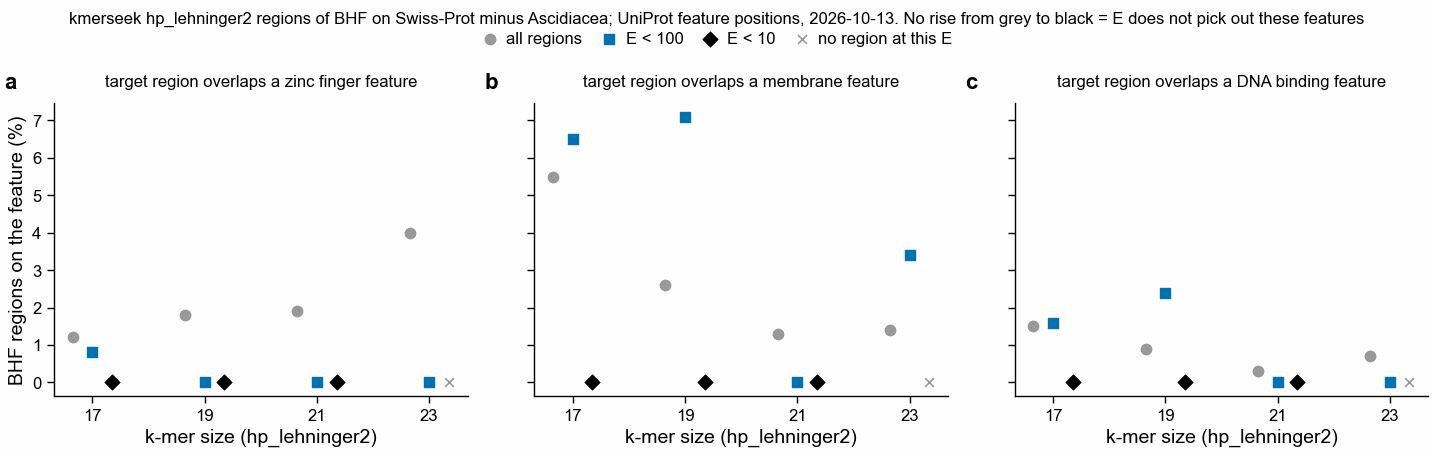

In [12]:
FEAT_RE = re.compile(
    r"(ZN_FING|TRANSMEM|INTRAMEM|DNA_BIND|LIPID) [<>?]?(\d+)(?:\.\.[<>?]?(\d+))?"
)
FEAT_GROUP = {
    "ZN_FING": "zinc finger",
    "TRANSMEM": "membrane",
    "INTRAMEM": "membrane",
    "LIPID": "membrane",
    "DNA_BIND": "DNA binding",
}
FEATS = ["zinc finger", "membrane", "DNA binding"]
target_feats = {}
for r in feat_tsv.iter_rows(named=True):
    spans = []
    for col in [
        "Zinc finger",
        "Transmembrane",
        "Intramembrane",
        "DNA binding",
        "Lipidation",
    ]:
        for m in FEAT_RE.finditer(r[col]):
            spans.append(
                (
                    FEAT_GROUP[m.group(1)],
                    int(m.group(2)) - 1,
                    int(m.group(3) or m.group(2)),
                )
            )  # 0-based, end-exclusive
    target_feats[r["Entry"]] = spans
missing = set(kr["target_name"]) - set(target_feats)
assert not missing, f"{len(missing)} targets have no UniProt row"
kf = kr.with_columns(
    *[
        pl.struct("target_name", "target_start", "target_end")
        .map_elements(
            lambda r, f=f: any(
                g == f and s < r["target_end"] and e > r["target_start"]
                for g, s, e in target_feats[r["target_name"]]
            ),
            return_dtype=pl.Boolean,
        )
        .alias(f)
        for f in FEATS
    ]
)
TIERS = {
    "all regions": pl.lit(True),
    "E < 100": pl.col("region_evalue") < 100,
    "E < 10": pl.col("region_evalue") < 10,
}
feat_tab = pl.concat(
    [
        kf.filter(cond)
        .group_by("k")
        .agg(
            pl.len().alias("regions"),
            *[pl.col(f).sum().alias(f"on {f}") for f in FEATS],
        )
        .with_columns(pl.lit(t).alias("regions with"))
        for t, cond in TIERS.items()
    ]
)
feat_tab = (
    pl.DataFrame({"k": BHF_KS})
    .join(pl.DataFrame({"regions with": list(TIERS)}), how="cross")
    .join(feat_tab, on=["k", "regions with"], how="left")
    .fill_null(0)
    .with_columns(
        *[
            (100 * pl.col(f"on {f}") / pl.col("regions")).round(1).alias(f"% on {f}")
            for f in FEATS
        ]
    )
)
print(feat_tab)
feat_tab.write_csv(
    TABLES
    / "279_bhf_regions_on_target_zinc_finger_membrane_dna_binding_hp_lehninger2_swissprot.csv"
)
print("\nRegions with E < 100 that land on one of the features:")
print(
    kf.filter((pl.col("region_evalue") < 100) & pl.any_horizontal(FEATS))
    .sort("region_evalue")
    .with_columns(
        pl.col("target_name")
        .replace_strict(uniprot_name, default="")
        .str.slice(0, 45)
        .alias("target_description")
    )
    .select(
        "k",
        "target_name",
        "target_description",
        "region_start",
        "region_end",
        "target_start",
        "target_end",
        pl.col("region_evalue").round(1),
        *FEATS,
    )
)
print(
    "BHF itself: predicted transmembrane helices",
    sm.stretches(tm) or "none",
    "; cysteines",
    bhf_seq.count("C"),
)

TIER_MARK = {
    "all regions": ("o", pf.GREY),
    "E < 100": ("s", pf.OKABE_ITO["blue"]),
    "E < 10": ("D", "black"),
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 58, ncols=3, sharey=True)
for ax, f in zip(axs, FEATS):
    for i, (t, (mk, col)) in enumerate(TIER_MARK.items()):
        sub = feat_tab.filter((pl.col("regions with") == t) & (pl.col("regions") > 0))
        ax.scatter(
            sub["k"] + (i - 1) * 0.35,
            sub[f"% on {f}"],
            marker=mk,
            s=14,
            color=col,
            label=f"{t}" if f == FEATS[0] else None,
        )
        for kk in feat_tab.filter(
            (pl.col("regions with") == t) & (pl.col("regions") == 0)
        )["k"]:
            ax.scatter(
                [kk + (i - 1) * 0.35],
                [0],
                marker="x",
                s=10,
                color=pf.GREY,
                lw=0.6,
                label="no region at this E" if f == FEATS[0] and kk == 23 else None,
            )
    ax.set_xticks(BHF_KS)
    ax.set_xlabel("k-mer size (hp_lehninger2)")
    ax.set_title(f"target region overlaps a {f} feature", fontsize=6)
axs[0].set_ylabel("BHF regions on the feature (%)")
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=4,
    title=(
        "kmerseek hp_lehninger2 regions of BHF on Swiss-Prot minus Ascidiacea; UniProt feature positions, 2026-10-13. "
        "No rise from grey to black = E does not pick out these features"
    ),
    title_fontsize=6,
)
pf.save(
    fig,
    FIG / "279_bhf_regions_on_zinc_finger_membrane_dna_binding_hp_lehninger2_swissprot",
)

### 6e. Residues of every region left

Every BHF region with E < 10 that passes any of the three low-complexity rules of 6c. Five lines per
region, 60 columns per block: BHF's residues, BHF's H/P string, the target's H/P string,
the target's residues, and a mark line: `|` where the residues are identical, `^` where the
column is inside an exact shared H/P k-mer and the residues differ, `!` where both hold.

In [13]:
left = bhf_ann.filter(
    pl.col("share of the region") | pl.col("share of the shared k-mers")
).sort("k", "region_evalue")
print(f"{left.height} regions left, {left['target_name'].n_unique()} targets\n")
for r in left.iter_rows(named=True):
    assert r["region_n_chained"] == 1, "the mark line assumes a region of one piece"
    _, cols, _ = seed_offsets(r)
    cols = set(cols)
    q, t = r["region_subseq"], r["target_subseq"]
    marks = "".join(
        "!" if (a == b and i in cols) else "|" if a == b else "^" if i in cols else " "
        for i, (a, b) in enumerate(zip(q, t))
    )
    print(
        f"k{r['k']}  {r['target_name']} {r['target_description']}  E = {r['region_evalue']:.2f}; "
        f"{r['region_n_shared_kmers']} shared k-mers; {r['identical_residues']} of {len(q)} residues identical; "
        f"kept by: {', '.join(x for x in RULES[1:] if r[x])}"
    )
    for i in range(0, len(q), 60):
        lab_q = f"BHF {r['region_start'] + 1 + i}"
        lab_t = f"{r['target_name']} {r['target_start'] + 1 + i}"
        for lab, s in [
            (lab_q, q),
            ("BHF H/P", to_hp(q)),
            ("target H/P", r["moltype_seq"]),
            (lab_t, t),
            ("", marks),
        ]:
            print(f"{lab:>18}  {s[i:i + 60]}")
        print()

7 regions left, 6 targets

k17  Q69TH6 Putative 12-oxophytodienoate reductase 3 (EC   E = 2.97; 2 shared k-mers; 14 of 108 residues identical; kept by: share of the region, share of the shared k-mers, shared k-mers, both proteins
             BHF 1  MVHDTEQLLAQGHHEEETECGKYGKLPEKGSECKKHGIFCRILTALHLKKRRTEHDHQKL
           BHF H/P  hhppppphhhphpppppppphphhphhpphpppppphhhpphhphhphppppppppppph
        target H/P  hhphphphhhphhhhhpppphphhphhhphhppphhhhhpphhphhphpppppphphphh
         Q69TH6 72  GVSATGEGYPEIPGVWTRQQVKAWKPIVDAVHRKGALFFCQLAHVGRASTNDQQPNGQAP
                     |  |                |  |        |  ^^!!^^^^^^^^^^^^^^   |  

            BHF 61  LSESQEHLDASTKKTKKKAKKDKRKNKPPKKDSETSKPAQTTISRLPS
           BHF H/P  hpppppphphpppppppphpppppppphhpppppppphhppphpphhp
        target H/P  hpppppphphppppphhpphpphpppphhphhpphphhhpphhphhhp
        Q69TH6 132  ISSTDKQITPDDSHTVYSKPRRLRTDEIPHVVDDFRVAARNAIEAGFD
                     |            |        |    |         |   |     

k17  O36421 Unchar

### 6f. Why kmerseek gives BHF no small E-value

phmmer's best hit on BHF is the Vpx protein of simian immunodeficiency virus (P27984,
E = 0.16, BHF 137-190). This part asks whether kmerseek finds the same place, and if it does,
why its E-value for it is large. It reads phmmer's own alignments of BHF to its seven
targets (`bhf_phmmer.out`), and for each alignment counts the identical residues, the
columns where both residues are in the same H/P class, and the longest unbroken run of such
columns. An exact shared H/P 17-mer needs a run of at least 17.

**The arithmetic.** Under H/P, one aligned column can only say "same class" or "different
class". If a column matches by chance with probability p, a run of L matching columns
starting at a given pair of positions happens by chance with probability about p^L. A search
of BHF against the index tries about N = (BHF k-mer positions) x (index k-mers) starting
pairs, so a run of L is expected by chance about N x p^L times, and a run is unlikely by
chance (expected count below 1) only when L > log(N) / log(1/p). p comes from the share of
hydrophobic residues in BHF and in the targets (estimated from the 15_207 targets of BHF's
regions, `bhf_targets_k17_k23.fasta`, not the whole reference). This ignores kmerseek's
k-mer weights and its extension through mismatches; it only sets the scale.

phmmer's alignments of BHF, scored column by column (H/P = hp_lehninger2 classes):
┌────────┬────────────────────────────────┬─────────────────┬───────────────┬───────────────────┬─────────────────────┬──────────┬───────────┬─────────┐
│ target ┆ target_name                    ┆ aligned_columns ┆ identical_pct ┆ same_HP_class_pct ┆ longest_same_HP_run ┆ phmmer_E ┆ bhf_start ┆ bhf_end │
│ ---    ┆ ---                            ┆ ---             ┆ ---           ┆ ---               ┆ ---                 ┆ ---      ┆ ---       ┆ ---     │
│ str    ┆ str                            ┆ i64             ┆ i64           ┆ i64               ┆ i64                 ┆ f64      ┆ i64       ┆ i64     │
╞════════╪════════════════════════════════╪═════════════════╪═══════════════╪═══════════════════╪═════════════════════╪══════════╪═══════════╪═════════╡
│ P27984 ┆ Protein Vpx                    ┆ 54              ┆ 28            ┆ 80                ┆ 26                  ┆ 0.16     ┆ 137       ┆ 190     │


Hydrophobic share: BHF 0.381, targets 0.503; chance that a column has the same H/P class p = 0.499
┌─────┬─────────────┬───────────────────┬───────────────────────────┬──────────────────┬───────────────────────────────┬───────────────────┐
│ k   ┆ index_kmers ┆ possible_HP_kmers ┆ chance_copies_of_one_kmer ┆ starting_pairs_N ┆ run_needed_for_chance_below_1 ┆ chance_runs_of_26 │
│ --- ┆ ---         ┆ ---               ┆ ---                       ┆ ---              ┆ ---                           ┆ ---               │
│ i64 ┆ i64         ┆ i64               ┆ f64                       ┆ i64              ┆ i64                           ┆ i64               │
╞═════╪═════════════╪═══════════════════╪═══════════════════════════╪══════════════════╪═══════════════════════════════╪═══════════════════╡
│ 17  ┆ 166224750   ┆ 131072            ┆ 1268.2                    ┆ 39229041000      ┆ 36                            ┆ 563               │
│ 19  ┆ 166040019   ┆ 524288            ┆ 316.7       

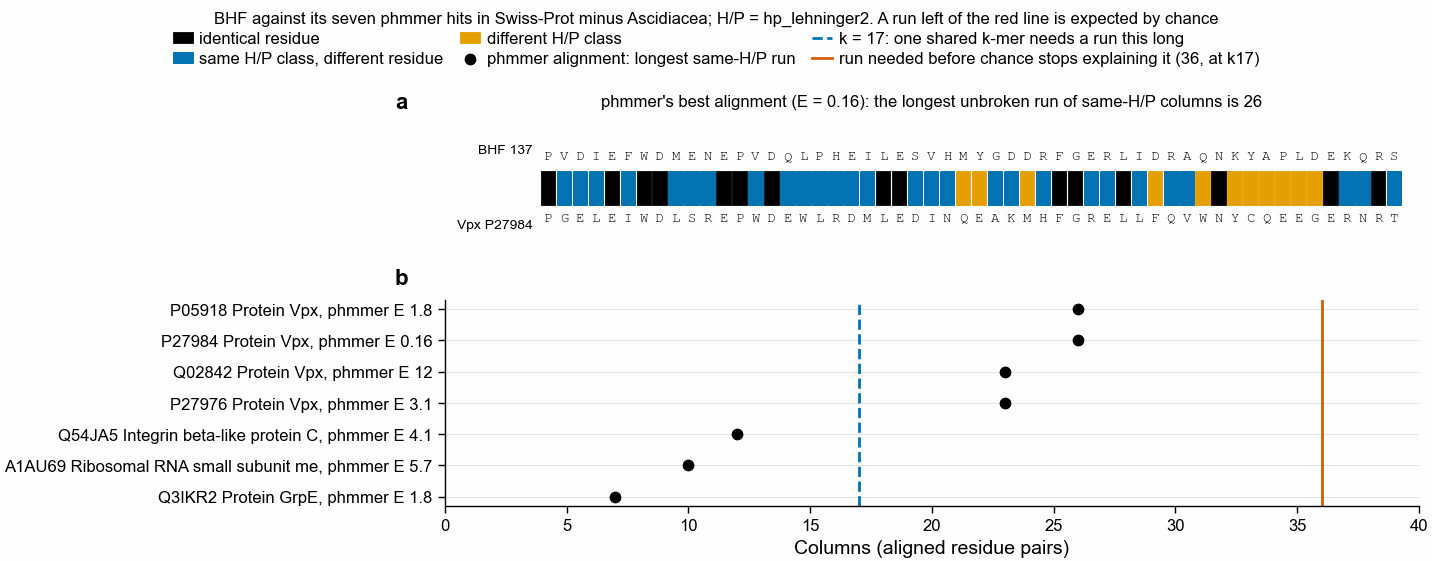

In [14]:
import math

# phmmer's alignments of BHF, one row per domain: residues on both sides, gaps kept
phmmer_aln = []
for block in phmmer_text.split("\n>> ")[1:]:
    target = block.split()[0]
    for dblock in block.split("  == domain ")[1:]:
        q_aln = t_aln = ""
        q_from = None  # BHF position of the first aligned residue
        lines = dblock.splitlines()[1:]
        i = 0
        while i < len(lines):
            m = re.match(rf"\s+{BHF_ID}\s+(\d+)\s+(\S+)\s+(\d+)", lines[i])
            if m:
                if q_from is None:
                    q_from = int(m.group(1))
                q_aln += m.group(2)
                t_aln += re.match(r"\s+\S+\s+\d+\s+(\S+)\s+\d+", lines[i + 2]).group(1)
                i += 4
                continue
            if lines[i].startswith(">>") or "Internal pipeline" in lines[i]:
                break
            i += 1
        phmmer_aln.append(
            {
                "target": target,
                "bhf_from": q_from,
                "q": q_aln.upper(),
                "t": t_aln.upper(),
            }
        )


def hp_runs(q, t):
    # per column: 2 identical residue, 1 same H/P class, 0 different class, -1 gap on either side
    col = [
        (
            -1
            if not (a.isalpha() and b.isalpha())
            else 2 if a == b else 1 if (a in HP_H) == (b in HP_H) else 0
        )
        for a, b in zip(q, t)
    ]
    run = best = 0
    for c in col:
        run = run + 1 if c >= 1 else 0
        best = max(best, run)
    return col, best


rows = []
for a in phmmer_aln:
    a_col, a_best = hp_runs(a["q"], a["t"])
    n = sum(c >= 0 for c in a_col)
    rows.append(
        {
            "target": a["target"],
            "target_name": uniprot_name.get(
                a["target"], names.get(a["target"], "")
            ).split(" (")[0][:30],
            "aligned_columns": n,
            "identical_pct": round(100 * sum(c == 2 for c in a_col) / n),
            "same_HP_class_pct": round(100 * sum(c >= 1 for c in a_col) / n),
            "longest_same_HP_run": a_best,
        }
    )
aln_tab = pl.DataFrame(rows).join(
    dom.select(
        "target", pl.col("evalue").alias("phmmer_E"), "bhf_start", "bhf_end"
    ).unique("target"),
    on="target",
    how="left",
)
# kmerseek's region on the same targets, per k
km_on = kr.filter(pl.col("target_name").is_in(aln_tab["target"].to_list())).select(
    "k",
    pl.col("target_name").alias("target"),
    pl.col("region_start").alias("km_bhf_start0"),
    "region_end",
    pl.col("region_n_shared_kmers").cast(pl.Int64).alias("shared_kmers"),
    pl.col("region_evalue").round(0).alias("kmerseek_E"),
    pl.col("query_poisson_pvalue").cast(pl.Float64).alias("protein_poisson_p"),
)
print(
    "phmmer's alignments of BHF, scored column by column (H/P = hp_lehninger2 classes):"
)
print(aln_tab.sort("phmmer_E"))
print("\nkmerseek regions on the same targets (BHF positions 0-based, end-exclusive):")
print(km_on.sort("target", "k"))

# How long a run of matching H/P columns has to be before chance stops explaining it
tseqs = read_fasta(BHF / "bhf_targets_k17_k23.fasta")
f_bhf = sum(c in HP_H for c in bhf_seq) / len(bhf_seq)
f_ref = sum(sum(c in HP_H for c in s) for s in tseqs.values()) / sum(
    len(s) for s in tseqs.values()
)
p_same = f_bhf * f_ref + (1 - f_bhf) * (1 - f_ref)
need_rows = []
for k in BHF_KS:
    n_index = int(kr.filter(pl.col("k") == k)["db_n_kmers"][0])
    n_pairs = (len(bhf_seq) - k + 1) * n_index
    need_rows.append(
        {
            "k": k,
            "index_kmers": n_index,
            "possible_HP_kmers": 2**k,
            "chance_copies_of_one_kmer": round(n_index / 2**k, 1),
            "starting_pairs_N": n_pairs,
            "run_needed_for_chance_below_1": math.ceil(
                math.log(n_pairs) / -math.log(p_same)
            ),
            "chance_runs_of_26": round(n_pairs * p_same**26),
        }
    )
need = pl.DataFrame(need_rows)
print(
    f"\nHydrophobic share: BHF {f_bhf:.3f}, targets {f_ref:.3f}; chance that a column has the same H/P class p = {p_same:.3f}"
)
print(need)

# Protein-level Poisson p-value: does it single out Vpx? (BHF's targets, and the copies' best)
prot_p = (
    kr.filter(pl.col("k") == 17)
    .group_by("target_name")
    .agg(pl.col("query_poisson_pvalue").cast(pl.Float64).min().alias("p"))
    .sort("p")
)
print(
    f"\nk17: BHF targets with protein Poisson p = 0: {(prot_p['p'] == 0).sum():_} of {prot_p.height:_}; "
    f"targets with p at or below P27984's ({prot_p.filter(pl.col('target_name') == 'P27984')['p'][0]:.1e}): "
    f"{(prot_p['p'] <= prot_p.filter(pl.col('target_name') == 'P27984')['p'][0]).sum():_}"
)

# The figure: the Vpx alignment column by column, and every alignment's longest run against what is needed
COL_STYLE = {
    2: ("identical residue", "black"),
    1: ("same H/P class, different residue", pf.OKABE_ITO["blue"]),
    0: ("different H/P class", pf.OKABE_ITO["orange"]),
    -1: ("gap", "white"),
}
need17 = need.filter(pl.col("k") == 17)["run_needed_for_chance_below_1"][0]
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 72, nrows=2, gridspec_kw={"height_ratios": [1, 1.6]}
)
ax = axs[0]
vpx = next(a for a in phmmer_aln if a["target"] == "P27984")
vpx_col, vpx_best = hp_runs(vpx["q"], vpx["t"])
for x, c in enumerate(vpx_col):
    lab, colour = COL_STYLE[c]
    ax.add_patch(
        plt.Rectangle(
            (x, 0),
            0.9,
            1,
            facecolor=colour,
            edgecolor="black" if c == -1 else colour,
            lw=0.3,
        )
    )
    ax.text(
        x + 0.45,
        1.25,
        vpx["q"][x],
        ha="center",
        va="bottom",
        fontsize=5,
        family="monospace",
    )
    ax.text(
        x + 0.45,
        -0.25,
        vpx["t"][x],
        ha="center",
        va="top",
        fontsize=5,
        family="monospace",
    )
for c in sorted(set(vpx_col), reverse=True):  # one legend entry per column type present
    lab, colour = COL_STYLE[c]
    ax.add_patch(
        plt.Rectangle(
            (0, 0),
            0,
            0,
            facecolor=colour,
            edgecolor="black" if c == -1 else colour,
            lw=0.3,
            label=lab,
        )
    )
ax.set_xlim(-6, len(vpx_col) + 1)
ax.set_ylim(-1.4, 2.4)
ax.text(-0.5, 1.6, f"BHF {vpx['bhf_from']}", ha="right", va="center", fontsize=5)
ax.text(-0.5, -0.6, "Vpx P27984", ha="right", va="center", fontsize=5)
ax.axis("off")
ax.set_title(
    f"phmmer's best alignment (E = 0.16): the longest unbroken run of same-H/P columns is {vpx_best}",
    fontsize=6,
)

ax = axs[1]
aln_order = aln_tab.sort("longest_same_HP_run")
ys = range(aln_order.height)
ax.scatter(
    aln_order["longest_same_HP_run"],
    ys,
    color="black",
    s=14,
    zorder=3,
    label="phmmer alignment: longest same-H/P run",
)
ax.axvline(
    17,
    color=pf.OKABE_ITO["blue"],
    lw=1,
    ls="--",
    label="k = 17: one shared k-mer needs a run this long",
)
ax.axvline(
    need17,
    color=pf.OKABE_ITO["vermillion"],
    lw=1,
    label=f"run needed before chance stops explaining it ({need17}, at k17)",
)
ax.set_yticks(
    list(ys),
    [
        f"{r['target']} {r['target_name']}, phmmer E {r['phmmer_E']:g}"
        for r in aln_order.iter_rows(named=True)
    ],
)
ax.set_xlim(0, need17 + 4)
ax.set_xlabel("Columns (aligned residue pairs)")
for y in ys:
    ax.axhline(y, color="#dddddd", lw=0.3, zorder=0)
for a_, letter in zip(axs, "ab"):
    pf.panel_label(a_, letter)
pf.shared_legend(
    fig,
    ncol=3,
    title="BHF against its seven phmmer hits in Swiss-Prot minus Ascidiacea; H/P = hp_lehninger2. "
    "A run left of the red line is expected by chance",
    title_fontsize=6,
)
pf.save(
    fig, FIG / "279_bhf_phmmer_alignments_hp_runs_vs_chance_hp_lehninger2_swissprot"
)

### 6h. Every setting, not only hp_lehninger2

Sections 6-6g look at hp_lehninger2 k17-k23 only. The run searched BHF under every alphabet,
k-mer size and scaled value: 230 kmerseek settings. The run's report lists, for each, the
best region on BHF (`multiqc_dark_landmark_0_plot.txt`, the "Hero query" table of the
*B. schlosseri* report). Copied from
`results-0.4/botryllus/botryllus_dark_set_multiqc_data/` on Sherlock on 2026-10-13.

For every setting whose best region has E < 1, the run's per-task file of BHF's regions
(`<chunk>.<setting>.landmarks.csv`, every region of BHF, every target) was copied from the
run's work folder to `bhf-view/landmarks/`, and every region with E < 1 gets the three
low-complexity rules of 6c. Each alphabet's letters are read from the regions themselves:
the target's residues sit beside their letters in `moltype_seq`.

**Caution, written before the regions were read.** The chance control of 6c covers
hp_lehninger2 only. Here the best of about 135 settings with E-values is taken, so a small
best E-value is expected even with no relative; one setting in a hundred reaching E = 0.01
is what chance alone gives if the E-values are right. A setting's result counts as a
candidate only if a region passes rule 3, and even then it needs its own shuffle control.

In [15]:
LANDMARK_TABLE = BHF / "multiqc" / "multiqc_dark_landmark_0_plot.txt"
hero = pl.read_csv(LANDMARK_TABLE, separator="\t", infer_schema_length=0).with_columns(
    pl.col("evalue").cast(pl.Float64, strict=False)
)
km = hero.filter(pl.col("Sample").str.starts_with("kmerseek")).with_columns(
    pl.col("Sample").str.extract(r"kmerseek (\S+) k\d+").alias("alphabet"),
    pl.col("Sample").str.extract(r" k(\d+)").cast(pl.Int64).alias("ksize"),
    pl.col("Sample")
    .str.extract(r"scaled (\d+)")
    .cast(pl.Int64)
    .fill_null(1)
    .alias("scaled"),
)
km = km.with_columns(
    pl.col("alphabet").str.extract(r"(\d+)$").cast(pl.Int64).alias("letters")
)
print(
    f"kmerseek settings: {km.height}; put a region on BHF: {(km['found'] == 'yes').sum()}; "
    f"with a best E-value (extend arms): {km['evalue'].is_not_null().sum()}"
)
print(
    "Tools:",
    hero.filter(~pl.col("Sample").str.starts_with("kmerseek"))
    .select("Sample", "found", "evalue", "best_target")
    .rows(),
)
cut_tab = pl.DataFrame(
    [
        {"best_E_below": c, "kmerseek_settings": int((km["evalue"] < c).sum())}
        for c in [0.001, 0.01, 0.1, 1, 10]
    ]
)
print(cut_tab)
print(
    km.filter(pl.col("evalue") < 1)
    .sort("evalue")
    .select(
        "Sample", "evalue", "best_target", "query_region", "target_region", "n_regions"
    )
)

# Every BHF region with E < 1 in those settings, from the run's landmark files
LANDMARKS = BHF / "landmarks"
lm = {}
for f in sorted(LANDMARKS.glob("*.landmarks.csv")):
    lm[f.name.split(".lcfalse")[0].removeprefix("chunk_0004.")] = (
        pl.read_csv(f, infer_schema_length=0)
        .filter(pl.col("query_name") == BHF_ID)
        .with_columns(
            pl.col("region_evalue").cast(pl.Float64),
            pl.col(
                "region_start",
                "region_end",
                "target_start",
                "target_end",
                "region_n_shared_kmers",
                "region_n_chained",
                "ksize",
            ).cast(pl.Int64),
        )
    )
# Each alphabet's letters, learned from every file that uses it (a small file may not show every residue)
amaps = {}
for setting, d in lm.items():
    amap = amaps.setdefault(setting.split(".")[0], {})
    for r in d.filter(pl.col("region_n_chained") == 1).iter_rows(named=True):
        for a, letter in zip(r["target_subseq"], r["moltype_seq"]):
            assert (
                amap.setdefault(a, letter) == letter
            ), f"{setting}: {a} has two letters"
for name, amap in amaps.items():
    assert set(bhf_seq) <= set(
        amap
    ), f"{name}: BHF residues with no letter: {set(bhf_seq) - set(amap)}"
    print(
        f"{name}: "
        + " ".join(
            "".join(sorted(a for a in amap if amap[a] == L))
            for L in sorted(set(amap.values()))
        )
    )
rows = []
for setting, d in lm.items():
    encode = lambda s, m=amaps[setting.split(".")[0]]: "".join(m[c] for c in s)
    for r in (
        d.filter(pl.col("region_evalue") < 1)
        .rename({"ksize": "k"})
        .iter_rows(named=True)
    ):
        _, qcols, tcols = seed_offsets(r, encode)
        s0, e0 = r["region_start"], r["region_end"]
        tmask = sm.low_complexity_mask(r["target_subseq"])
        rows.append(
            {
                "setting": setting,
                "target": r["target_name"],
                "E": r["region_evalue"],
                "start": s0,
                "end": e0,
                "tstart": r["target_start"],
                "tend": r["target_end"],
                "shared_kmers": r["region_n_shared_kmers"],
                "found_kmers": len(_),
                "chained": r["region_n_chained"],
                "region_lc": sum(lc[s0:e0]) / (e0 - s0),
                "seed_lc": sum(lc[s0 + j] for j in qcols) / len(qcols),
                "target_seed_lc": sum(tmask[j] for j in tcols) / len(tcols),
                "identical": (
                    sum(a == b for a, b in zip(r["region_subseq"], r["target_subseq"]))
                    if r["region_n_chained"] == 1
                    else None
                ),
                "q": r["region_subseq"],
                "t": r["target_subseq"],
                "qenc": encode(r["region_subseq"]),
                "tenc": r["moltype_seq"],
                "qcols": qcols,
                "k": r["k"],
            }
        )
low = pl.DataFrame(rows).with_columns(
    (pl.col("region_lc") < 0.5).alias(RULES[1]),
    (pl.col("seed_lc") < 0.5).alias(RULES[2]),
    ((pl.col("seed_lc") < 0.5) & (pl.col("target_seed_lc") < 0.5)).alias(RULES[3]),
)
# Scaled 1 keeps every k-mer, so the count must match; scaled 10 keeps about 1 in 10, so kmerseek
# counts only the kept ones and the exact matches found here can be more (their columns are used).
s1 = ~low["setting"].str.contains(r"\.s10")
assert (
    low.filter(s1)["found_kmers"] == low.filter(s1)["shared_kmers"]
).all(), "scaled 1: count differs from kmerseek's"
assert (
    low.filter(~s1)["found_kmers"] >= low.filter(~s1)["shared_kmers"]
).all(), "scaled 10: fewer found than kmerseek's"
print(
    f"\nShared k-mers found = region_n_shared_kmers in all {s1.sum()} scaled-1 regions with E < 1; "
    f"at least kmerseek's count in the {(~s1).sum()} scaled-10 regions"
)
low_tab = (
    low.group_by("setting")
    .agg(
        pl.len().alias("regions_E_below_1"),
        pl.col("E").min().alias("best_E"),
        *[pl.col(rule).sum().alias(f"kept_{i}") for i, rule in enumerate(RULES[1:], 1)],
        pl.col("E").filter(pl.col(RULES[3])).min().alias("best_E_kept_by_rule_3"),
    )
    .sort("best_E")
)
print(low_tab)
low_tab.write_csv(
    TABLES / "279_bhf_all_settings_regions_E_below_1_low_complexity_swissprot.csv"
)
print(f"Settings with E < 1 read here: {low_tab.height} of {(km['evalue'] < 1).sum()}")

kmerseek settings: 230; put a region on BHF: 141; with a best E-value (extend arms): 133
Tools: [('jackhmmer (sequence)', 'yes', 0.16, 'P27984'), ('mmseqs2 (sequence)', 'no', None, None), ('phmmer (sequence)', 'yes', 0.16, 'P27984')]
┌──────────────┬───────────────────┐
│ best_E_below ┆ kmerseek_settings │
│ ---          ┆ ---               │
│ f64          ┆ i64               │
╞══════════════╪═══════════════════╡
│ 0.001        ┆ 1                 │
│ 0.01         ┆ 2                 │
│ 0.1          ┆ 3                 │
│ 1.0          ┆ 10                │
│ 10.0         ┆ 62                │
└──────────────┴───────────────────┘
┌─────────────────────────────────┬──────────┬─────────────┬──────────────┬───────────────┬───────────┐
│ Sample                          ┆ evalue   ┆ best_target ┆ query_region ┆ target_region ┆ n_regions │
│ ---                             ┆ ---      ┆ ---         ┆ ---          ┆ ---           ┆ ---       │
│ str                             ┆ f64      ┆ 

gbmr4: X ABDEKNQRSTZ G P CFHILMVWY
hp_lehninger_c_nonpolar2: ACFGILMPVWY DEHKNQRST
hp_lehninger_hpc3: X C AFGILMPVWY BDEHKNQRST
hp_thomas_dill2: X ACFILMVWY DEGHKNPQRSTZ
hp_thomas_dill_no_c2: X AFILMVWY CDEGHKNPQRST

Shared k-mers found = region_n_shared_kmers in all 157 scaled-1 regions with E < 1; at least kmerseek's count in the 4 scaled-10 regions
┌─────────────────────────────────┬───────────────────┬──────────┬────────┬────────┬────────┬───────────────────────┐
│ setting                         ┆ regions_E_below_1 ┆ best_E   ┆ kept_1 ┆ kept_2 ┆ kept_3 ┆ best_E_kept_by_rule_3 │
│ ---                             ┆ ---               ┆ ---      ┆ ---    ┆ ---    ┆ ---    ┆ ---                   │
│ str                             ┆ u32               ┆ f64      ┆ u32    ┆ u32    ┆ u32    ┆ f64                   │
╞═════════════════════════════════╪═══════════════════╪══════════╪════════╪════════╪════════╪═══════════════════════╡
│ gbmr4.k16.s1                    ┆ 84                ┆ 

3 regions with E < 1 keep their shared k-mers outside low complexity on both proteins

hp_lehninger_hpc3.k17.s1  Q9QJ59 Protein B4  E = 0.22; 2 shared 17-mers; 8 of 60 residues identical
           BHF 188  QRSESHGAGEYLKHQWKGQGAKKARKRIRTVMKATWQSLQAGARSQTAFLNPQGAVSAAL
       BHF letters  pppppphhhphhppphphphhpphppphpphhphphpphphhhpppphhhphphhhphhh
    target letters  pphphhhhphhpphhhphpphpchhpphpphhphphpphphhhhphhphpphhhhhphph
        Q9QJ59 101  RSAHPPVGRFYTRPLFSLSRATCGPSSGTSAPRPRWRSLTLGGAHGPRGRSLFPPASPRL
                              |         |    ^^^^^^^^^^!^!!^^!^             |  |

hp_lehninger_c_nonpolar2.k21.s10  P33313 Hsp70/Hsp90 co-chaperone CNS1 (Cyclophilin seven s  E = 0.58; 1 shared 21-mers; 5 of 91 residues identical
           BHF 150  VDQLPHEILESVHMYGDDRFGERLIDRAQNKYAPLDEKQRSESHGAGEYLKHQWKGQGAK
       BHF letters  hpphhpphhpphphhhppphhpphhpphppphhhhppppppppphhhphhppphphphhp
    target letters  hpphhpphppphpphhphpphpphpphhpphhhhphpppphppphhhpphhhphphpphp
         P33313 

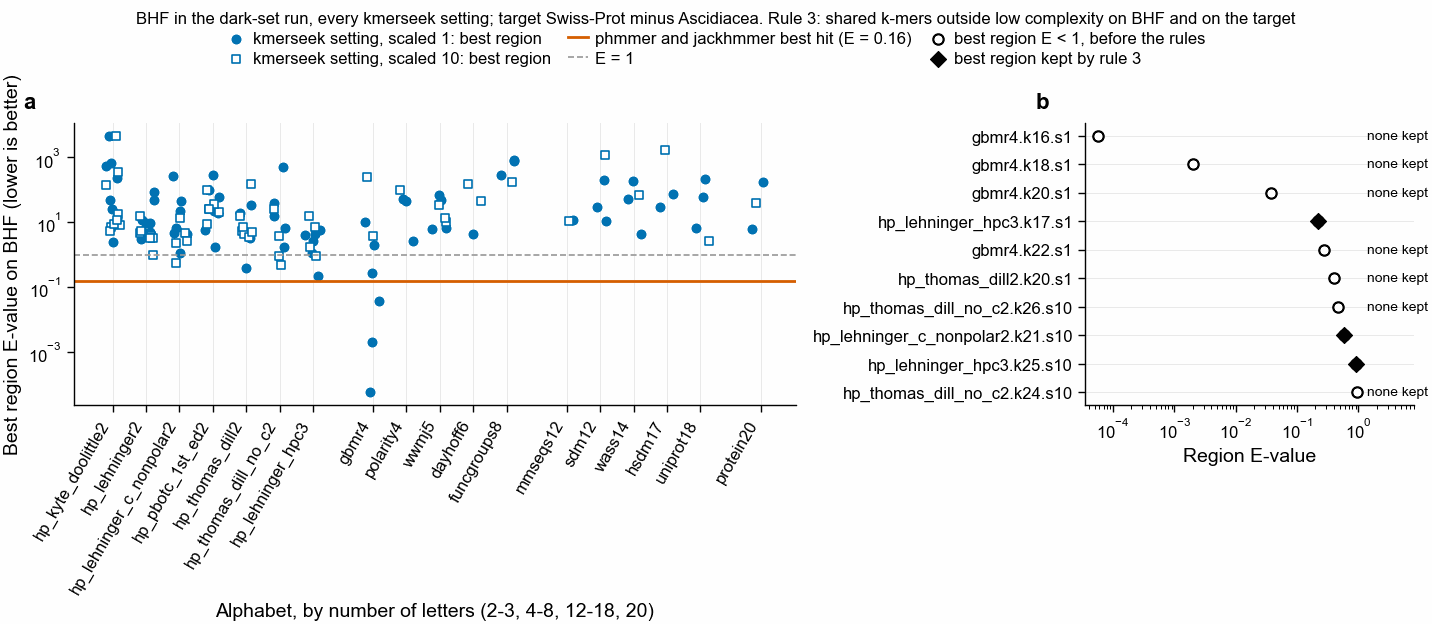

In [16]:
# Residues of every region with E < 1 that rule 3 keeps
kept3 = low.filter(pl.col(RULES[3])).sort("E")
print(
    f"{kept3.height} regions with E < 1 keep their shared k-mers outside low complexity on both proteins\n"
)
for r in kept3.iter_rows(named=True):
    cols = set(r["qcols"])
    marks = "".join(
        "!" if (a == b and i in cols) else "|" if a == b else "^" if i in cols else " "
        for i, (a, b) in enumerate(zip(r["q"], r["t"]))
    )
    print(
        f"{r['setting']}  {r['target']} {uniprot_name.get(r['target'], '')[:50]}  E = {r['E']:.2g}; "
        f"{r['shared_kmers']} shared {r['k']}-mers; {r['identical']} of {len(r['q'])} residues identical"
    )
    for i in range(0, len(r["q"]), 60):
        for lab, s in [
            (f"BHF {r['start'] + 1 + i}", r["q"]),
            ("BHF letters", r["qenc"]),
            ("target letters", r["tenc"]),
            (f"{r['target']} {r['tstart'] + 1 + i}", r["t"]),
            ("", marks),
        ]:
            print(f"{lab:>18}  {s[i:i + 60]}")
        print()
dropped = (
    low.filter(~pl.col(RULES[3])).sort("E").unique("setting", keep="first").sort("E")
)
print("Best region each setting loses to rule 3, with residues:")
for r in dropped.iter_rows(named=True):
    print(
        f"\n{r['setting']}  {r['target']} {uniprot_name.get(r['target'], '')[:40]}  E = {r['E']:.2g}; shared k-mers in low "
        f"complexity: BHF {r['seed_lc']:.0%}, target {r['target_seed_lc']:.0%}"
    )
    print(f"{'BHF ' + str(r['start'] + 1):>18}  {r['q'][:80]}")
    print(f"{r['target'] + ' ' + str(r['tstart'] + 1):>18}  {r['t'][:80]}")

# Figure: (a) every setting's best E-value by alphabet; (b) the settings with E < 1, before and after rule 3
alph = (
    km.filter(pl.col("evalue").is_not_null())
    .group_by("alphabet")
    .agg(pl.col("letters").first())
    .sort("letters", "alphabet")
)
order_x, xpos, x, prev = [], {}, 0, None
for a, n in alph.iter_rows():
    grp = 0 if n <= 3 else 1 if n <= 8 else 2 if n <= 18 else 3
    if prev is not None and grp != prev:
        x += 0.8  # gap between alphabet-size groups
    xpos[a] = x
    order_x.append(a)
    x += 1
    prev = grp
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 80, ncols=2, gridspec_kw={"width_ratios": [2.2, 1]}
)
ax = axs[0]
SCALED_MARK = {1: ("o", "scaled 1"), 10: ("s", "scaled 10")}
for sc, (mk, lab) in SCALED_MARK.items():
    sub = km.filter(pl.col("evalue").is_not_null() & (pl.col("scaled") == sc))
    jit = np.random.default_rng(sc).uniform(-0.25, 0.25, sub.height)
    ax.scatter(
        [xpos[a] + j for a, j in zip(sub["alphabet"], jit)],
        sub["evalue"],
        marker=mk,
        s=9,
        facecolor=pf.OKABE_ITO["blue"] if sc == 1 else "white",
        edgecolor=pf.OKABE_ITO["blue"],
        lw=0.6,
        label=f"kmerseek setting, {lab}: best region",
    )
ph = hero.filter(pl.col("Sample") == "phmmer (sequence)")["evalue"][0]
ax.axhline(
    ph,
    color=pf.OKABE_ITO["vermillion"],
    lw=1,
    label=f"phmmer and jackhmmer best hit (E = {ph:g})",
)
ax.axhline(1, color=pf.GREY, lw=0.6, ls="--", label="E = 1")
ax.set_yscale("log")
ax.set_xticks([xpos[a] for a in order_x], order_x, rotation=60, ha="right")
for a in order_x:
    ax.axvline(xpos[a], color="#e6e6e6", lw=0.3, zorder=0)
ax.set_ylabel("Best region E-value on BHF (lower is better)")
ax.set_xlabel("Alphabet, by number of letters (2-3, 4-8, 12-18, 20)")
ax = axs[1]
lt = low_tab.sort("best_E", descending=True)
ys = list(range(lt.height))
ax.scatter(
    lt["best_E"],
    ys,
    marker="o",
    s=14,
    facecolor="white",
    edgecolor="black",
    lw=0.8,
    label="best region E < 1, before the rules",
)
kept_e = lt["best_E_kept_by_rule_3"]
ax.scatter(
    [e for e in kept_e if e is not None],
    [y for y, e in zip(ys, kept_e) if e is not None],
    marker="D",
    s=16,
    color="black",
    label="best region kept by rule 3",
)
for y, e in zip(ys, kept_e):
    if e is None:
        ax.text(1.4, y, "none kept", va="center", fontsize=5)
ax.set_xscale("log")
ax.set_xlim(right=8)
ax.set_yticks(ys, lt["setting"])
for y in ys:
    ax.axhline(y, color="#e6e6e6", lw=0.3, zorder=0)
ax.set_xlabel("Region E-value")
for a_, letter in zip(axs, "ab"):
    pf.panel_label(a_, letter)
pf.shared_legend(
    fig,
    ncol=3,
    title=(
        "BHF in the dark-set run, every kmerseek setting; target Swiss-Prot minus Ascidiacea. "
        "Rule 3: shared k-mers outside low complexity on BHF and on the target"
    ),
    title_fontsize=6,
)
pf.save(fig, FIG / "279_bhf_all_settings_best_evalue_and_low_complexity_swissprot")

**What 6h shows.** kmerseek put a region on BHF in 141 of 230 settings, and 10 settings have a
best region with E < 1, more than hp_lehninger2 alone suggests. The smallest, gbmr4 k16 at
E = 5.8e-5, and every other region below E = 0.2 fail rule 3: their shared k-mers sit in
low-complexity stretches. gbmr4 writes K, R, E, D, S, T, N, Q and A as one letter, so BHF's
lysine run (KTKKKAKKDKRKNK) reads the same as a glutamate run (O36421, EEEEEEEEDDEEEEE), an
arginine run (P9WIG2, RRQRRQRRQ) or a serine and glutamate stretch (Q9SIH2, SSSESEAE). Three regions
with E < 1 pass rule 3, at E = 0.22, 0.58 and 0.93, with 8 of 60, 5 of 91 and 2 of 28
identical residues. Among about 133 settings with E-values, regions near E = 1 are what
chance gives, so none of them is a candidate without its own shuffle control.

### 6g. Data for the BHF explainer page

The interactive page that explains this section is built by `scripts/make_bhf_explainer.py`
from the JSON this cell writes, so every number on the page is one printed above.

In [17]:
import json


def _f(x):
    return None if x is None or (isinstance(x, float) and math.isnan(x)) else x


def region_record(r):
    _, qcols, _ = seed_offsets(r)
    return {
        "k": r["k"],
        "target": r["target_name"],
        "name": uniprot_name.get(r["target_name"], ""),
        "E": r["region_evalue"],
        "start": r["region_start"],
        "end": r["region_end"],
        "tstart": r["target_start"],
        "tend": r["target_end"],
        "q": r["region_subseq"],
        "t": r["target_subseq"],
        "thp": r["moltype_seq"],
        "seeds": qcols,
        "shared_kmers": r["region_n_shared_kmers"],
        "identical": r["identical_residues"],
        "region_lc": round(r["region_lc_share"], 3),
        "seed_lc": round(r["seed_lc_share"], 3),
        "target_seed_lc": round(r["target_seed_lc_share"], 3),
        "rules": {rule: bool(r[rule]) for rule in RULES[1:]},
    }


explainer = {
    "bhf": {
        "id": BHF_ID,
        "seq": bhf_seq,
        "lc": [list(x) for x in sm.stretches(lc)],
        "hp_h": "".join(sorted(HP_H)),
    },
    "phmmer": [
        {
            "target": r["target"],
            "name": r["target_name"],
            "E": r["phmmer_E"],
            "start": r["bhf_start"],
            "end": r["bhf_end"],
        }
        for r in aln_tab.sort("phmmer_E").iter_rows(named=True)
    ],
    "vpx_alignment": {
        "bhf_from": vpx["bhf_from"],
        "q": vpx["q"],
        "t": vpx["t"],
        "longest_run": vpx_best,
    },
    "alignments": aln_tab.sort("phmmer_E").to_dicts(),
    "kmerseek_on_phmmer_targets": km_on.sort("target", "k").to_dicts(),
    # kmerseek's own region on Vpx P27984 at each k, residues and shared k-mer columns
    "vpx_regions": [
        {
            "k": r["k"],
            "start": r["region_start"],
            "end": r["region_end"],
            "tstart": r["target_start"],
            "tend": r["target_end"],
            "E": r["region_evalue"],
            "shared_kmers": int(r["region_n_shared_kmers"]),
            "q": r["region_subseq"],
            "t": r["target_subseq"],
            "thp": r["moltype_seq"],
            "seeds": seed_offsets(r)[1],
        }
        for r in kr.filter(pl.col("target_name") == "P27984")
        .with_columns(pl.col("region_n_chained").cast(pl.Int64))
        .sort("k")
        .iter_rows(named=True)
    ],
    "regions_E_below_10": [
        region_record(r)
        for r in bhf_ann.sort("k", "region_evalue").iter_rows(named=True)
    ],
    "region_counts": kr.group_by("k")
    .agg(
        pl.len().alias("regions"),
        (pl.col("region_evalue") < 10).sum().alias("E_below_10"),
    )
    .sort("k")
    .to_dicts(),
    "shuffle": {
        "rules": RULES,
        "per_query": [
            {k_: _f(v) for k_, v in d.items()}
            for d in bhf_per.with_columns(
                (pl.col("query_name") == BHF_ID).alias("is_bhf")
            )
            .drop("query_name")
            .to_dicts()
        ],
        "summary": [{k_: _f(v) for k_, v in d.items()} for d in lc_tab.to_dicts()],
    },
    "chance": {
        "p_same": p_same,
        "f_bhf": f_bhf,
        "f_targets": f_ref,
        "need": need.to_dicts(),
    },
    "protein_p": {
        "zero": int((prot_p["p"] == 0).sum()),
        "targets": prot_p.height,
        "at_or_below_vpx": int(
            (
                prot_p["p"] <= prot_p.filter(pl.col("target_name") == "P27984")["p"][0]
            ).sum()
        ),
    },
    "features": [{k_: _f(v) for k_, v in d.items()} for d in feat_tab.to_dicts()],
    "feature_nearest": {
        f: kf.filter(pl.col(f))
        .sort("region_evalue")
        .select(
            "k",
            pl.col("target_name").alias("target"),
            pl.col("region_evalue").alias("E"),
        )
        .row(0, named=True)
        | {
            "name": uniprot_name.get(
                kf.filter(pl.col(f)).sort("region_evalue")["target_name"][0], ""
            ).split(" (")[0]
        }
        for f in FEATS
    },
    "seed_counts": {
        "table": seed_tab.to_dicts(),
        "per_query": seed.select("k", "query", *SEED_MEASURES).to_dicts(),
    },
    "all_settings": {
        "best": km.select(
            "Sample",
            "alphabet",
            "letters",
            "ksize",
            "scaled",
            "found",
            pl.col("evalue").alias("E"),
            "best_target",
        ).to_dicts(),
        "tools_E": hero.filter(pl.col("Sample") == "phmmer (sequence)")["evalue"][0],
        "low_tab": [{k_: _f(v) for k_, v in d.items()} for d in low_tab.to_dicts()],
        "kept": [
            {
                "setting": r["setting"],
                "target": r["target"],
                "name": uniprot_name.get(r["target"], ""),
                "E": r["E"],
                "k": r["k"],
                "start": r["start"],
                "end": r["end"],
                "tstart": r["tstart"],
                "q": r["q"],
                "t": r["t"],
                "seeds": r["qcols"],
                "identical": r["identical"],
                "shared_kmers": r["shared_kmers"],
            }
            for r in kept3.iter_rows(named=True)
        ],
        "dropped": [
            {
                "setting": r["setting"],
                "target": r["target"],
                "name": uniprot_name.get(r["target"], ""),
                "E": r["E"],
                "start": r["start"],
                "end": r["end"],
                "tstart": r["tstart"],
                "q": r["q"],
                "t": r["t"],
                "seed_lc": r["seed_lc"],
                "target_seed_lc": r["target_seed_lc"],
            }
            for r in dropped.iter_rows(named=True)
        ],
        "gbmr4_groups": " ".join(
            "".join(
                sorted(
                    a
                    for a in amaps["gbmr4"]
                    if amaps["gbmr4"][a] == L and a not in "BXZ"
                )
            )
            for L in sorted(set(amaps["gbmr4"].values()))
            if any(a not in "BXZ" for a in amaps["gbmr4"] if amaps["gbmr4"][a] == L)
        ),
    },
}
EXPLAINER_JSON = TABLES / "279_bhf_explainer_data.json"
EXPLAINER_JSON.write_text(json.dumps(explainer, separators=(",", ":")))
print(
    f"wrote {EXPLAINER_JSON}: {EXPLAINER_JSON.stat().st_size / 1e3:.0f} kB, "
    f"{len(explainer['regions_E_below_10'])} regions with E < 10, {len(explainer['shuffle']['per_query'])} query x k x rule rows"
)

wrote ../tables/279_bhf_explainer_data.json: 262 kB, 10 regions with E < 10, 1616 query x k x rule rows


## 7. Reach after dropping low-complexity and helix regions

Every kmerseek region on a dark protein (no tool hit with E < 1) under the six settings selected
before the query-summary repair, with region E < 10, was pulled from the run's region files and
scored by `tools/dark-regions` (PR 57): the share of its residues, on the query and on the
target, that sit in a low-complexity stretch (SEG first pass) or a predicted transmembrane
helix (Kyte-Doolittle), read on the full sequences. A region is **dropped** when at least
`MAX_MASKED_SHARE` of its residues are low complexity or helix on either side. A dark protein
is **reached after filtering** when at least one of its regions is kept.

Placed proteins' regions were not extracted, so after filtering there is no placed share to
compare with; the counts below are dark proteins only. The settings in this panel were
selected before the query-summary repair. Some are no longer the qualifying winners.
The current E < 10 winners for human, worm and Botryllus have no region-mask extraction
here, so this panel does not measure filtering for every current winner. kmerseek 0.4.0 gives some target names
another sequence's coordinates (kmerseek PR 141); `target_coords` says which rows were moved
to where their residues really are, or not found in the named target.

Regions per species and how their target coordinates checked out:
┌───────────┬───────────┬────────┬───────┐
│ species   ┆ not_found ┆ match  ┆ moved │
│ ---       ┆ ---       ┆ ---    ┆ ---   │
│ str       ┆ u32       ┆ u32    ┆ u32   │
╞═══════════╪═══════════╪════════╪═══════╡
│ human     ┆ 4350      ┆ 124460 ┆ 836   │
│ worm      ┆ 5490      ┆ 339969 ┆ 763   │
│ yeast     ┆ 171       ┆ 12023  ┆ null  │
│ borrelia  ┆ 23        ┆ 1544   ┆ null  │
│ botryllus ┆ 6821      ┆ 270883 ┆ 211   │
└───────────┴───────────┴────────┴───────┘
not extracted: borrelia protein20 k5 (best at E < 10); left out of this section
Historical pre-repair choice: original summary counts against region counts; current winners are in section 3
┌─────────────┬───────────┬──────────────────────────────┬───────────────────────┬──────────────┐
│ tool_cutoff ┆ species   ┆ setting                      ┆ section3_dark_reached ┆ dark_reached │
│ ---         ┆ ---       ┆ ---                          ┆ ---             

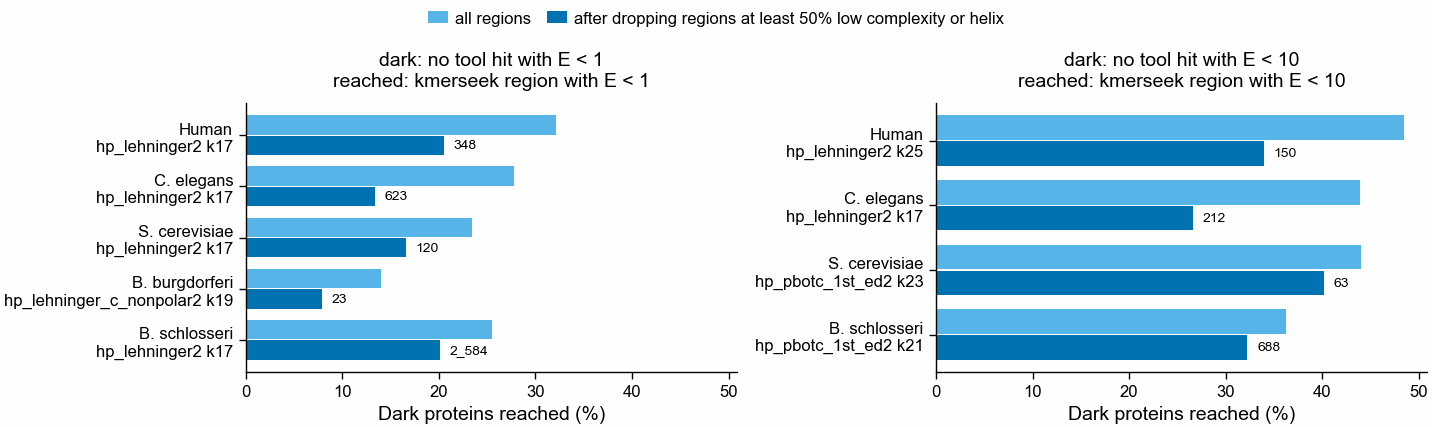

In [18]:
original_reach = pl.read_csv(
    TABLES / "279_dark_set_kmerseek_reach_scaled1_original_2026_10_12_qfo_swissprot.csv"
)
original_best = (
    original_reach.filter(pl.col("tells_dark_from_placed"))
    .sort(
        ["dark_share", "placed_share", "alphabet", "ksize"],
        descending=[True, True, False, False],
    )
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", maintain_order=True)
    .head(1)
)

MAX_MASKED_SHARE = (
    0.5  # drop a region when at least this share of it is low complexity or helix
)
DR = Path("/Users/olga/data/invertebrate-dark-set/results-0.4/dark-regions")
regions = pl.concat(
    [
        pl.read_csv(
            DR / f"{s}_dark_regions.csv.gz",
            infer_schema_length=0,
            schema_overrides={"query_name": pl.String, "target_name": pl.String},
        ).with_columns(pl.lit(s).alias("species"))
        for s in SPECIES
    ]
)
num = ["region_start", "region_end", "target_start", "target_end", "ksize", "scaled"]
regions = regions.with_columns(
    pl.col(num).cast(pl.Int64),
    pl.col("region_evalue", "query_lc", "query_tm", "target_lc", "target_tm").cast(
        pl.Float64
    ),
    pl.col("moltype").alias("alphabet"),
)
regions = regions.with_columns(
    (
        pl.max_horizontal("query_lc", "query_tm", "target_lc", "target_tm")
        >= MAX_MASKED_SHARE
    ).alias("dropped")
)
print("Regions per species and how their target coordinates checked out:")
print(
    regions.group_by("species", "target_coords")
    .len()
    .pivot(on="target_coords", index="species", values="len")
    .sort(pl.col("species").replace_strict(order))
)

EXTRACTED = set(regions.select("species", "alphabet", "ksize").unique().iter_rows())
after = []
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t).filter(pl.col("dark"))
    for r in original_best.filter(
        (pl.col("tool_cutoff") == t)
        & (pl.col("kmerseek_cutoff") == k)
        & pl.col("alphabet").is_not_null()
    ).iter_rows(named=True):
        if (r["species"], r["alphabet"], r["ksize"]) not in EXTRACTED:
            print(
                f"not extracted: {r['species']} {r['alphabet']} k{r['ksize']} (best at E < {k:g}); left out of this section"
            )
            continue
        g = regions.filter(
            (pl.col("species") == r["species"])
            & (pl.col("alphabet") == r["alphabet"])
            & (pl.col("ksize") == r["ksize"])
            & (pl.col("scaled") == SCALED)
            & (pl.col("region_evalue") < k)
        ).join(
            flags.select(pl.col("accession").alias("query_name"), "species"),
            on=["species", "query_name"],
        )
        before_n = g["query_name"].n_unique()
        kept_n = g.filter(~pl.col("dropped"))["query_name"].n_unique()
        after.append(
            {
                "tool_cutoff": float(t),
                "kmerseek_cutoff": float(k),
                "species": r["species"],
                "setting": f"{r['alphabet']} k{r['ksize']}",
                "dark_proteins": r["dark_proteins"],
                "dark_reached": before_n,
                "dark_reached_after_filter": kept_n,
            }
        )
after = pl.DataFrame(after).with_columns(
    (pl.col("dark_reached") / pl.col("dark_proteins")).alias("share_before"),
    (pl.col("dark_reached_after_filter") / pl.col("dark_proteins")).alias(
        "share_after"
    ),
)
check = after.join(
    original_best.select(
        "tool_cutoff",
        "kmerseek_cutoff",
        "species",
        pl.col("dark_reached").alias("section3_dark_reached"),
    ),
    on=["tool_cutoff", "kmerseek_cutoff", "species"],
)
print(
    "Historical pre-repair choice: original summary counts against region counts; current winners are in section 3"
)
print(
    check.select(
        "tool_cutoff", "species", "setting", "section3_dark_reached", "dark_reached"
    )
)
print(after.with_columns(pl.col("share_before", "share_after").round(3)))

fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 55, ncols=len(CUTOFF_PAIRS), sharex=True, squeeze=False
)
for c, (t, k) in enumerate(CUTOFF_PAIRS):
    ax = axs[0][c]
    d = after.filter(
        (pl.col("tool_cutoff") == t) & (pl.col("kmerseek_cutoff") == k)
    ).sort(pl.col("species").replace_strict(order))
    ys = list(range(d.height))[::-1]
    ax.barh(
        [y + 0.2 for y in ys],
        100 * d["share_before"],
        height=0.38,
        color=pf.OKABE_ITO["sky_blue"],
        label="all regions",
    )
    ax.barh(
        [y - 0.2 for y in ys],
        100 * d["share_after"],
        height=0.38,
        color=pf.OKABE_ITO["blue"],
        label=f"after dropping regions at least {MAX_MASKED_SHARE:.0%} low complexity or helix",
    )
    for y, a, n in zip(ys, d["share_after"], d["dark_reached_after_filter"]):
        ax.text(100 * a + 1, y - 0.2, f"{n:_}", va="center", fontsize=5)
    ax.set_yticks(
        ys, [f"{SPECIES_NAME[s]}\n{st}" for s, st in zip(d["species"], d["setting"])]
    )
    ax.set_xlabel("Dark proteins reached (%)")
    ax.set_title(
        f"dark: no tool hit with E < {t:g}\nreached: kmerseek region with E < {k:g}"
    )
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / f"279_dark_reach_after_lowcomplexity_helix_filter_scaled{SCALED}")

## 8. What the filtered regions on *B. schlosseri* dark proteins match

*B. schlosseri* gene models have no names, so each kept region is described by its Swiss-Prot
target. Terms for immune, histocompatibility, MHC and allorecognition proteins are searched
in the target names; the list is in the code cell, and a name matches when it contains any
term (case is ignored). The table lists every kept region whose target name matches, with the
residues of the best one per target family.


dark: no tool hit with E < 1; kmerseek region E < 1; six settings pooled
  kept regions 7_500 on 3_566 dark proteins; 8 regions on 7 dark proteins match an immune term
┌────────────────┬───────────────┬─────────┬────────────┐
│ immune_term    ┆ dark_proteins ┆ regions ┆ smallest_E │
│ ---            ┆ ---           ┆ ---     ┆ ---        │
│ str            ┆ u32           ┆ u32     ┆ f64        │
╞════════════════╪═══════════════╪═════════╪════════════╡
│ lectin         ┆ 2             ┆ 3       ┆ 0.714629   │
│ immunoglobulin ┆ 2             ┆ 2       ┆ 0.846669   │
│ interleukin    ┆ 2             ┆ 2       ┆ 0.513936   │
│ interferon     ┆ 1             ┆ 1       ┆ 0.835135   │
└────────────────┴───────────────┴─────────┴────────────┘
┌───────────────────────┬──────────────────┬───────┬─────────────┬─────────────────────────────────┬──────────────┬────────────┬───────────────┬──────────┬───────────┐
│ query_name            ┆ alphabet         ┆ ksize ┆ target_name ┆ target_descripti


Residues of the kept region with the smallest E-value per immune term:

FUN014101_FUN014101.2 25-193  vs  Q7TQN3 (WAP, Kazal, immunoglobulin, Kunitz and NTR domain-containing protein 2) 254-422, hp_lehninger2 k17, E = 0.847
  B. schlosseri  SLSMLLGGGILGLPDTLDKSGFYPFLVTFSLNYGIQVVVIHQMTEVLQYARVILSKSPDG
                 FSEAIGIRQHLDAVQDTSELQQQNTDYGTMGERSRNAVEGVNRTDSKYQNSELSGPNVYS
                 IGKLFLNRYMQAAFLFSILFVFISILTSYSLAGSQAYANILQISAGSVT
     target H/P  phphphhhpphhphhhhphphpphhhhppphpphhhhhphphhhphhphhphphppppph
                 phphhhhppphphhppppphppppphphphphppphphphhppppphpphpphphphhhp
                 hphhhhhpphhhhphhpphhhhphhhpppphhppphhhhhpphphpphp
         Q7TQN3  HVRGNVVVTNIAQLVIYNVQPQDAGIYTCTARNVAGVLRADFPLSVVRGGQARATSESSL
                 NGTAFPATECLKPPDSEDCGEEQTRWHFDAQANNCLTFTFGHCHHNLNHFETYEACMLAC
                 MSGPLAICSLPALQGPCKAYVPRWAYNSQTGLCQSFVYGGCEGNGNNFE

FUN025926_FUN025926 1-99  vs  Q8R4S8 (Cytokine receptor-like factor 2) 134-237, hp_pbotc_1st_ed2 k21, E =

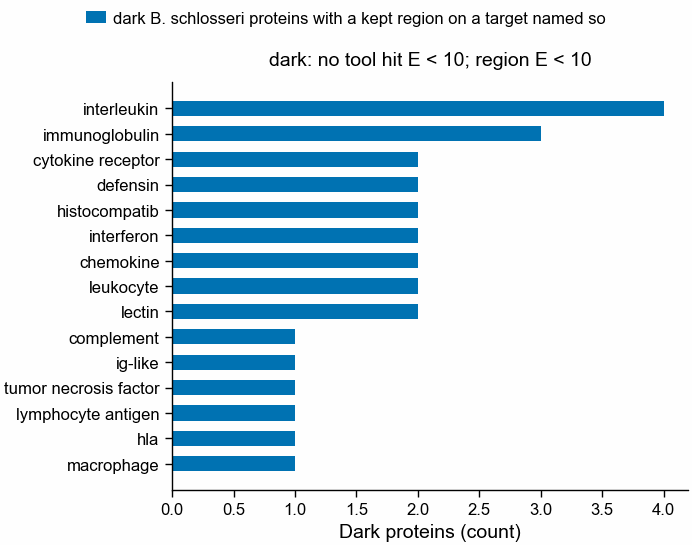

In [19]:
# Specific terms only: "antigen" alone matched "Cellular tumor antigen p53" and "Sperm-associated
# antigen", and "cytokine" matched "Dedicator of cytokinesis", none of them immune proteins.
IMMUNE_TERMS = [
    "histocompatib",
    "MHC",
    "HLA",
    "immunoglobulin",
    "Ig-like",
    "T-cell receptor",
    "B-cell receptor",
    "complement",
    "Toll-like",
    "interleukin",
    "interferon",
    "lectin",
    "killer cell",
    "leukocyte",
    "cytokine receptor",
    "chemokine",
    "tumor necrosis factor",
    "defensin",
    "perforin",
    "granzyme",
    "allorecogn",
    "lymphocyte antigen",
    "macrophage",
]
pattern = "(?i)(" + "|".join(re.escape(x) for x in IMMUNE_TERMS) + ")"
bot = regions.filter((pl.col("species") == "botryllus") & ~pl.col("dropped"))
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t).filter(pl.col("dark") & (pl.col("species") == "botryllus"))
    b = bot.filter(pl.col("region_evalue") < k).join(
        flags.select(pl.col("accession").alias("query_name")), on="query_name"
    )
    b = b.with_columns(
        pl.col("target_description")
        .str.extract(pattern, 1)
        .str.to_lowercase()
        .alias("immune_term")
    )
    imm = b.filter(pl.col("immune_term").is_not_null())
    print(
        f"\ndark: no tool hit with E < {t:g}; kmerseek region E < {k:g}; six settings pooled"
    )
    print(
        f"  kept regions {b.height:_} on {b['query_name'].n_unique():_} dark proteins; "
        f"{imm.height:_} regions on {imm['query_name'].n_unique():_} dark proteins match an immune term"
    )
    print(
        imm.group_by("immune_term")
        .agg(
            pl.col("query_name").n_unique().alias("dark_proteins"),
            pl.len().alias("regions"),
            pl.col("region_evalue").min().alias("smallest_E"),
        )
        .sort("dark_proteins", descending=True)
    )
    print(
        imm.sort("region_evalue")
        .unique(["query_name", "target_name"], keep="first", maintain_order=True)
        .head(25)
        .select(
            "query_name",
            "alphabet",
            "ksize",
            "target_name",
            "target_description",
            "region_start",
            "region_end",
            "region_evalue",
            pl.col("query_lc", "target_lc").round(2),
        )
    )
    if (t, k) == CUTOFF_PAIRS[-1]:
        imm_last = imm
        terms = (
            imm.group_by("immune_term")
            .agg(pl.col("query_name").n_unique().alias("dark_proteins"))
            .sort("dark_proteins")
        )

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
if terms.height:
    ax.barh(
        range(terms.height),
        terms["dark_proteins"],
        color=pf.OKABE_ITO["blue"],
        height=0.6,
        label="dark B. schlosseri proteins with a kept region on a target named so",
    )
    ax.set_yticks(range(terms.height), terms["immune_term"])
ax.set_xlabel("Dark proteins (count)")
t_last, k_last = CUTOFF_PAIRS[-1]
ax.set_title(f"dark: no tool hit E < {t_last:g}; region E < {k_last:g}")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / f"279_botryllus_dark_immune_target_terms_scaled{SCALED}")

print("\nResidues of the kept region with the smallest E-value per immune term:")
for r in (
    imm_last.sort("region_evalue")
    .unique("immune_term", keep="first", maintain_order=True)
    .iter_rows(named=True)
):
    print(
        f"\n{r['query_name']} {r['region_start'] + 1}-{r['region_end']}  vs  {r['target_name']} ({r['target_description']}) "
        f"{r['target_start'] + 1}-{r['target_end']}, {r['alphabet']} k{r['ksize']}, E = {r['region_evalue']:.3g}"
    )
    for lab, seq in [
        ("B. schlosseri", r["region_subseq"]),
        ("target H/P", r["moltype_seq"]),
        (r["target_name"], r["target_subseq"]),
    ]:
        for i in range(0, len(seq), 60):
            print(f"{lab if i == 0 else '':>15}  {seq[i:i + 60]}")

## 9. Dark and placed reach, corrected, for the six settings

Each protein's smallest finite region E-value under the six settings of section 7, read
straight from the run's region files by `tools/dark-regions min-evalue` (PR 57, f67c34a),
for every protein, dark or placed. The repaired summary export now supplies sections 2-3 for all settings. These independently
extracted region minima check the six previously selected settings against that export;
the original export is retained in the figure to show how much the counts changed.

files read per species: {'human': 66, 'worm': 60, 'yeast': 24, 'borrelia': 6, 'botryllus': 138}
Independent region minima agree with repaired query export on all 60 species/setting/cutoff rows
┌─────────────┬───────────┬──────────────────────────┬───────┬──────────────┬────────────┬────────────────────────┬────────────────┬──────────────┬──────────────────────────┬────────────────────────┐
│ tool_cutoff ┆ species   ┆ alphabet                 ┆ ksize ┆ dark_reached ┆ dark_share ┆ dark_share_queries_tsv ┆ placed_reached ┆ placed_share ┆ placed_share_queries_tsv ┆ tells_dark_from_placed │
│ ---         ┆ ---       ┆ ---                      ┆ ---   ┆ ---          ┆ ---        ┆ ---                    ┆ ---            ┆ ---          ┆ ---                      ┆ ---                    │
│ f64         ┆ str       ┆ str                      ┆ i64   ┆ u32          ┆ f64        ┆ f64                    ┆ u32            ┆ f64          ┆ f64                      ┆ bool                   │
╞══════

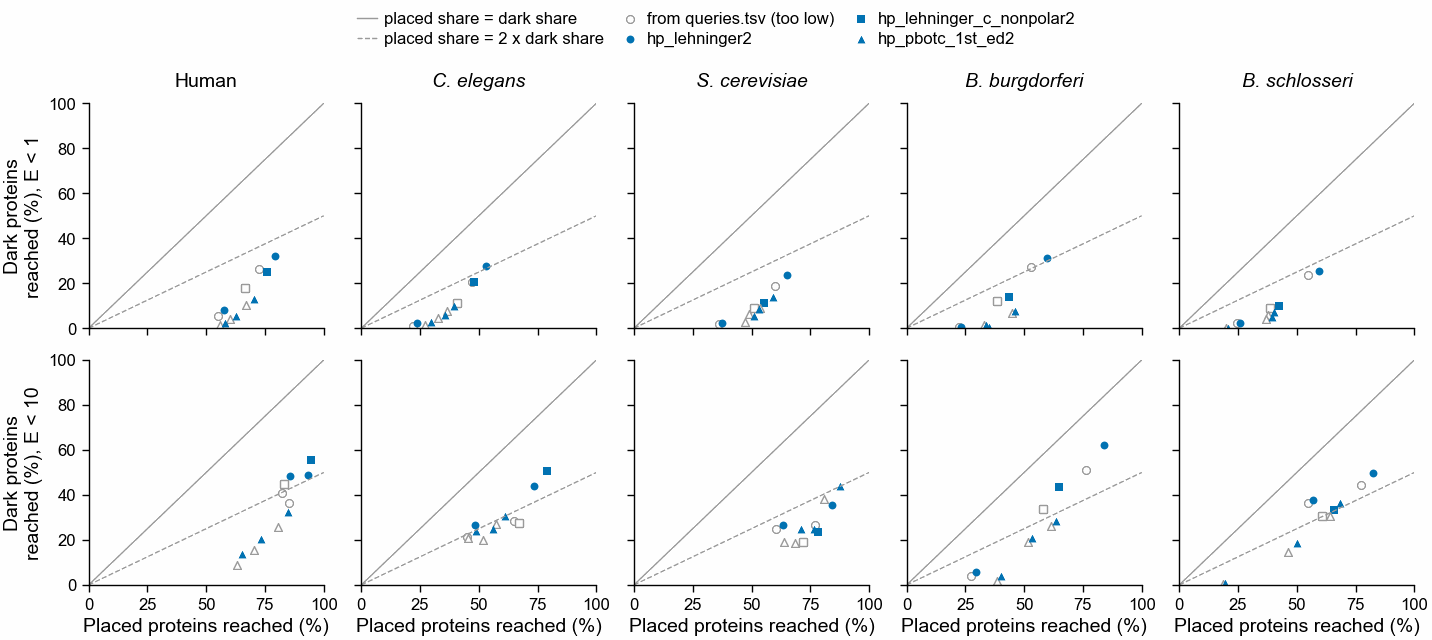

In [20]:
ME = Path("/Users/olga/data/invertebrate-dark-set/results-0.4/protein-min-evalue")
NAME_RE = r"^chunk_\d+\.(?P<alphabet>.+)\.k(?P<ksize>\d+)\.s(?P<scaled>\d+)\.lc"
me = pl.concat(
    [
        pl.read_csv(f, infer_schema_length=0).with_columns(pl.lit(sp).alias("species"))
        for sp in SPECIES
        for f in sorted((ME / sp).glob("*.csv.gz"))
    ]
)
me = (
    me.with_columns(pl.col("source_file").str.extract_groups(NAME_RE).alias("g"))
    .unnest("g")
    .with_columns(
        pl.col("ksize", "scaled").cast(pl.Int64),
        pl.col("min_region_evalue").cast(pl.Float64),
    )
)
me = me.group_by("species", "alphabet", "ksize", "scaled", "query_name").agg(
    pl.col("min_region_evalue").min()
)
print(
    "files read per species:",
    {sp: len(list((ME / sp).glob("*.csv.gz"))) for sp in SPECIES},
)

rows = []
for t, k in CUTOFF_PAIRS:
    flags = dark_flags(t)
    sizes = flags.group_by("species").agg(
        pl.col("dark").sum().alias("dark_proteins"),
        (~pl.col("dark")).sum().alias("placed_proteins"),
    )
    hit = me.filter(
        (pl.col("scaled") == SCALED) & (pl.col("min_region_evalue") < k)
    ).join(
        flags.rename({"accession": "query_name"}),
        on=["species", "query_name"],
        how="left",
    )
    if hit["dark"].null_count():
        raise ValueError(
            f"{hit['dark'].null_count()} reached proteins are not in the tool table"
        )
    c = hit.group_by("species", "alphabet", "ksize").agg(
        pl.col("dark").sum().alias("dark_reached"),
        (~pl.col("dark")).sum().alias("placed_reached"),
    )
    rows.append(
        c.join(sizes, on="species").with_columns(
            pl.lit(float(t)).alias("tool_cutoff"),
            pl.lit(float(k)).alias("kmerseek_cutoff"),
        )
    )
fixed = pl.concat(rows).with_columns(
    (pl.col("dark_reached") / pl.col("dark_proteins")).alias("dark_share"),
    (pl.col("placed_reached") / pl.col("placed_proteins")).alias("placed_share"),
)
fixed = fixed.with_columns(
    (pl.col("placed_share") >= MIN_PLACED_OVER_DARK * pl.col("dark_share")).alias(
        "tells_dark_from_placed"
    )
)
check = fixed.join(
    reach_all.select(
        "tool_cutoff",
        "kmerseek_cutoff",
        "species",
        "alphabet",
        "ksize",
        pl.col("dark_reached").alias("export_dark"),
        pl.col("placed_reached").alias("export_placed"),
    ),
    on=["tool_cutoff", "kmerseek_cutoff", "species", "alphabet", "ksize"],
    how="left",
)
assert check.height == fixed.height and check["export_dark"].null_count() == 0
assert check.filter(
    (pl.col("dark_reached") != pl.col("export_dark"))
    | (pl.col("placed_reached") != pl.col("export_placed"))
).is_empty()
print(
    f"Independent region minima agree with repaired query export on all {check.height} species/setting/cutoff rows"
)

old = pl.read_csv(
    TABLES / "279_dark_set_kmerseek_reach_scaled1_original_2026_10_12_qfo_swissprot.csv"
).select(
    "tool_cutoff",
    "kmerseek_cutoff",
    "species",
    "alphabet",
    "ksize",
    pl.col("dark_share").alias("dark_share_queries_tsv"),
    pl.col("placed_share").alias("placed_share_queries_tsv"),
)
fixed = fixed.join(
    old,
    on=["tool_cutoff", "kmerseek_cutoff", "species", "alphabet", "ksize"],
    how="left",
)
fixed = fixed.sort(
    "tool_cutoff",
    pl.col("species").replace_strict(order),
    "dark_share",
    descending=[False, False, True],
)
print(
    fixed.select(
        "tool_cutoff",
        "species",
        "alphabet",
        "ksize",
        "dark_reached",
        pl.col("dark_share", "dark_share_queries_tsv").round(3),
        "placed_reached",
        pl.col("placed_share", "placed_share_queries_tsv").round(3),
        "tells_dark_from_placed",
    )
)
TABLES.mkdir(exist_ok=True)
fixed.write_csv(
    TABLES
    / f"279_dark_set_kmerseek_reach_six_settings_region_files_scaled{SCALED}_qfo_swissprot.csv"
)

best_fixed = (
    fixed.filter(pl.col("tells_dark_from_placed"))
    .sort(
        ["dark_share", "placed_share", "alphabet", "ksize"],
        descending=[True, True, False, False],
    )
    .group_by("tool_cutoff", "kmerseek_cutoff", "species", maintain_order=True)
    .head(1)
)
verdict_fixed = (
    grid.join(best_fixed, on=["tool_cutoff", "kmerseek_cutoff", "species"], how="left")
    .group_by("tool_cutoff", "kmerseek_cutoff")
    .agg(
        (pl.col("dark_share").fill_null(0) >= MIN_DARK_SHARE)
        .sum()
        .alias("species_with_candidates"),
        pl.len().alias("species"),
    )
    .sort("tool_cutoff")
)
print("Decision rule on the corrected counts, six settings only:")
print(
    verdict_fixed.with_columns(
        (pl.col("species_with_candidates") == pl.col("species")).alias("rule_met")
    )
)

ALPHABET_MARK = {
    "hp_lehninger2": "o",
    "hp_lehninger_c_nonpolar2": "s",
    "hp_pbotc_1st_ed2": "^",
}
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM,
    34 * len(CUTOFF_PAIRS) + 14,
    nrows=len(CUTOFF_PAIRS),
    ncols=len(SPECIES),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for r_i, (t, k) in enumerate(CUTOFF_PAIRS):
    for c_i, sp in enumerate(SPECIES):
        ax = axs[r_i][c_i]
        d = fixed.filter((pl.col("tool_cutoff") == t) & (pl.col("species") == sp))
        ax.plot(
            [0, 100], [0, 100], color=pf.GREY, lw=0.5, label="placed share = dark share"
        )
        ax.plot(
            [0, 100],
            [0, 100 / MIN_PLACED_OVER_DARK],
            color=pf.GREY,
            lw=0.5,
            ls="--",
            label=f"placed share = {MIN_PLACED_OVER_DARK} x dark share",
        )
        for a, m in ALPHABET_MARK.items():
            e = d.filter(pl.col("alphabet") == a)
            ax.scatter(
                100 * e["placed_share_queries_tsv"],
                100 * e["dark_share_queries_tsv"],
                s=8,
                marker=m,
                facecolor="white",
                edgecolor=pf.GREY,
                lw=0.5,
                label="from queries.tsv (too low)" if a == "hp_lehninger2" else None,
            )
            ax.scatter(
                100 * e["placed_share"],
                100 * e["dark_share"],
                s=8,
                marker=m,
                color=pf.OKABE_ITO["blue"],
                lw=0,
                label=a,
            )
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)
        if r_i == 0:
            ax.set_title(
                SPECIES_NAME[sp], fontstyle="normal" if sp == "human" else "italic"
            )
        if c_i == 0:
            ax.set_ylabel(f"Dark proteins\nreached (%), E < {k:g}")
        if r_i == len(CUTOFF_PAIRS) - 1:
            ax.set_xlabel("Placed proteins reached (%)")
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / f"279_dark_vs_placed_reach_six_settings_region_files_scaled{SCALED}")

# Summary and Conclusions

## Background

The dark set is the proteins phmmer, jackhmmer and mmseqs2 all fail to place in Swiss-Prot
with the query's own clade removed. This notebook asks how many of them kmerseek puts a
region on, at E < 1 and E < 10 for both the tools and kmerseek, in human, *C. elegans*,
*S. cerevisiae*, *B. burgdorferi* and *B. schlosseri*, using the finished dark-set midi run
(PR 57). The repaired per-protein summaries refresh sections 2-6 without new searches. The
BHF analyses use the previously completed shuffle searches recorded below.

## Summary and Conclusions

* Loosening the tool cutoff shrinks the human dark set from 3_103 proteins (15.1%) at
  E < 0.001 to 1_696 (8.2%) at E < 1 and 442 (2.1%) at E < 10.
* Among settings whose placed share is at least twice the dark share, the repaired export
  reaches 14-32% of dark proteins at E < 1: hp_lehninger2 k17 in three species and
  hp_lehninger_c_nonpolar2 k19 in worm and Borrelia. At E < 10 the best qualifying settings
  reach 28-44%. The fixed rule is met in all five species at both cutoffs.
* For the historical settings selected before repair, dropping regions that are at least
  half low complexity or transmembrane helix leaves 8-21% of dark proteins reached at
  E < 1 and 27-40% at E < 10. These are not filter results for every current winner.
* Sections 2-6 now use repaired query summaries. Section 9 retains the original undercount
  for comparison and checks the repaired counts against independent region minima.
* On the corrected counts, the best of six H/P settings reaches 14-32% of dark proteins at
  E < 1 against 43-79% of placed proteins, in all five species.
* BHF is not dark at E < 1: phmmer and jackhmmer both hit the Vpx protein of simian
  immunodeficiency virus (P27984) at E = 0.16 on BHF residues 137-190.
* None of BHF's kmerseek regions under hp_lehninger2 k17-k23 has E < 1; the best is
  E = 2.97 at k17, and the strongest-ranked ones sit on BHF's lysine-rich low-complexity stretch.
* BHF's kmerseek regions are no better than chance: 100 dipeptide-shuffled copies of BHF,
  searched the same way, reach a median best E-value of 1.56 at k17, below BHF's 2.97, and
  BHF beats the copies at no k under any low-complexity rule (p = 0.42-0.65).
* Two BHF regions with E < 10 keep their shared k-mers outside low complexity on both
  proteins, both at k17: Q69TH6 (E = 2.97, 14 of 108 residues identical) and A0A089QRB9
  (E = 3.97, 8 of 96).
* No BHF region with E < 10 lands on a zinc finger, a membrane segment or a DNA-binding region
  of its target; the closest is a transmembrane segment of Q9UTN1 at E = 12.8.
* Over all 230 kmerseek settings, 10 give BHF a region with E < 1, the smallest E = 5.8e-5
  (gbmr4 k16). Every region below E = 0.2 has its shared k-mers in low complexity, such as
  BHF's lysine run against a glutamate or arginine run, which gbmr4 writes with one letter;
  the three that pass the low-complexity rule have E = 0.22-0.93 and 2-8 identical residues.
* kmerseek does find phmmer's Vpx match, at the same place: BHF 134-177 on Vpx (P27984) 9-52,
  with 10 shared 17-mers at k17, but scores it E = 2_873. H/P gives at most one bit per
  column: phmmer's alignment has 26 unbroken same-class columns, a search this size expects
  a run of 26 about 560 times by chance, and only a run of 36 or more would stand out.
* At k = 13-16, BHF shares at least 2 H/P k-mers with 2-9% more Swiss-Prot proteins than its
  shuffled copies (p = 0.04-0.05), but its best single protein shares fewer k-mers than the
  copies' median (p = 0.71-0.95), so no index below k17 was built for BHF.
* In *B. schlosseri*, 7 of 3_566 dark proteins reached at E < 1 after filtering match a
  target with an immune name, the best at E = 0.51 (interleukin-11).
* Under the six settings checked, no *B. schlosseri* dark protein reaches an MHC or
  histocompatibility target below E = 2.68, and those residues share only the H/P pattern.

## Analysis Details

The dark set at each cutoff comes from each protein's smallest phmmer, jackhmmer and mmseqs2
hit E-value; the tools ran with a reporting cutoff of 10, so every hit below 10 is kept.
kmerseek reach comes from each protein's smallest region E-value per setting. Section 2 draws
every alphabet and k-size at scaled 1: at E < 1 nearly all settings reach far more placed
than dark proteins; at E < 10 many sit on or near the "twice" line. Section 3 picks, per
species and cutoff, the setting with the largest dark share among those that reach placed
proteins at least twice as often. Section 4 lists the five dark proteins with the smallest
kmerseek E-value under that setting. These candidates still need inspection of their matched
regions; a small E-value alone does not establish a homolog. Section 5 compares UniProt features of dark
proteins reached against dark proteins missed. The pattern is not the same everywhere: in
*S. cerevisiae*, reached dark proteins carry compositional bias more often at both cutoffs:
44.7% against 20.4% at E < 1, and 28.1% against 8.0% at E < 10, and *B. burgdorferi* has too
few dark proteins (53 at E < 10) to read. UniProt features are whole-protein marks; whether a
kmerseek region sits inside a biased stretch or a helix is not checked here.

Sections 7-9 read the region coordinates from the run's region files and drop regions that
are mostly low complexity or transmembrane helix. Section 6 follows BHF alone: the H/P
k-mers it shares at k below 17 (6b), three low-complexity rules and a search of 100
dipeptide-shuffled copies of BHF against the same indexes (6c), UniProt zinc finger,
membrane and DNA-binding features under its regions' targets (6d), the residues of the
regions left (6e), why phmmer's Vpx match gets a large kmerseek E-value (6f), and every other
kmerseek setting's regions with E < 1 (6h). The shuffle search is the only new search in this notebook.

## Supplementary Information

- Cutoffs and the scaled setting are set in the first code cell (`CUTOFF_PAIRS`, `SCALED`).
- A protein counts below a cutoff when its E-value is strictly less than it. The pipeline's
  own dark set uses E <= 0.001, so one human and one *B. schlosseri* protein whose best hit is
  exactly 0.001 differ.
- Run: `runs/ladder-0.4-midi`, finished 2026-10-12, image `olgabot/kmerseek:0.4.0-rc5`,
  pipeline commit e3808d1 for the original searches; repaired summaries downloaded
  2026-10-23 from the completed PR 57 run. Export and source hashes are recorded in
  `tables/279_repaired_export_manifest.json.gz`.
- Settings without a Karlin-Altschul fit have no E-values
  and are not drawn.
- The repaired query summaries retain full *B. schlosseri* ids containing commas; the
  export validates every query id against the original conventional-tool query set.
- Output tables: `tables/279_dark_set_kmerseek_reach_scaled1_qfo_swissprot.csv`; for BHF,
  `tables/279_bhf_hp_lehninger2_seed_counts_vs_shuffles_swissprot.csv`,
  `tables/279_bhf_regions_low_complexity_vs_dipeptide_shuffles_hp_lehninger2_swissprot.csv`
  and `tables/279_bhf_regions_on_target_zinc_finger_membrane_dna_binding_hp_lehninger2_swissprot.csv`.
- BHF shuffle search: `scripts/279_bhf_shuffle_search.sbatch`, Slurm jobs 47649404, 47649408,
  47649416 and 47649421 (2026-10-13, image `olgabot/kmerseek:0.4.0-rc5`); copies in
  `data/279_bhf_dipeptide_shuffles.fasta` (md5 be46f47e612881a9ba1b21993c6ecc3a).

## References

- [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57): the dark-set pipeline
  and the export script.
- Notebook 274 ([PR 101](https://github.com/seanome/2024-kmerseek-analysis/pull/101)): the
  k-size range per alphabet.
- Notebook 240: Pfam dose-response with transmembrane instances held out.
- UniProt REST API, compositional bias (MobiDB-lite), repeat and transmembrane features,
  read 2026-10-12; zinc finger, membrane, DNA-binding and lipid features of BHF's targets,
  read 2026-10-13. https://rest.uniprot.org
- Altschul SF, Erickson BW (1985). Significance of nucleotide sequence alignments: a method
  for random sequence permutation that preserves dinucleotide and codon usage. Mol Biol Evol
  2:526-538. https://doi.org/10.1093/oxfordjournals.molbev.a040370
- Notebook 256 ([PR 83](https://github.com/seanome/2024-kmerseek-analysis/pull/83)): BHF
  against 300 dipeptide-shuffled copies, human proteome.

In [21]:
summary_md = r"""
# Summary and Conclusions

## Background

The dark set is the proteins phmmer, jackhmmer and mmseqs2 all fail to place in Swiss-Prot
with the query's own clade removed. This notebook asks how many of them kmerseek puts a
region on, at E < 1 and E < 10 for both the tools and kmerseek, in human, *C. elegans*,
*S. cerevisiae*, *B. burgdorferi* and *B. schlosseri*, using the finished dark-set midi run
(PR 57). The repaired per-protein summaries refresh sections 2-6 without new searches. The
BHF analyses use the previously completed shuffle searches recorded below.

## Summary and Conclusions

* Loosening the tool cutoff shrinks the human dark set from 3_103 proteins (15.1%) at
  E < 0.001 to 1_696 (8.2%) at E < 1 and 442 (2.1%) at E < 10.
* Among settings whose placed share is at least twice the dark share, the repaired export
  reaches 14-32% of dark proteins at E < 1: hp_lehninger2 k17 in three species and
  hp_lehninger_c_nonpolar2 k19 in worm and Borrelia. At E < 10 the best qualifying settings
  reach 28-44%. The fixed rule is met in all five species at both cutoffs.
* For the historical settings selected before repair, dropping regions that are at least
  half low complexity or transmembrane helix leaves 8-21% of dark proteins reached at
  E < 1 and 27-40% at E < 10. These are not filter results for every current winner.
* Sections 2-6 now use repaired query summaries. Section 9 retains the original undercount
  for comparison and checks the repaired counts against independent region minima.
* On the corrected counts, the best of six H/P settings reaches 14-32% of dark proteins at
  E < 1 against 43-79% of placed proteins, in all five species.
* BHF is not dark at E < 1: phmmer and jackhmmer both hit the Vpx protein of simian
  immunodeficiency virus (P27984) at E = 0.16 on BHF residues 137-190.
* None of BHF's kmerseek regions under hp_lehninger2 k17-k23 has E < 1; the best is
  E = 2.97 at k17, and the strongest-ranked ones sit on BHF's lysine-rich low-complexity stretch.
* BHF's kmerseek regions are no better than chance: 100 dipeptide-shuffled copies of BHF,
  searched the same way, reach a median best E-value of 1.56 at k17, below BHF's 2.97, and
  BHF beats the copies at no k under any low-complexity rule (p = 0.42-0.65).
* Two BHF regions with E < 10 keep their shared k-mers outside low complexity on both
  proteins, both at k17: Q69TH6 (E = 2.97, 14 of 108 residues identical) and A0A089QRB9
  (E = 3.97, 8 of 96).
* No BHF region with E < 10 lands on a zinc finger, a membrane segment or a DNA-binding region
  of its target; the closest is a transmembrane segment of Q9UTN1 at E = 12.8.
* Over all 230 kmerseek settings, 10 give BHF a region with E < 1, the smallest E = 5.8e-5
  (gbmr4 k16). Every region below E = 0.2 has its shared k-mers in low complexity, such as
  BHF's lysine run against a glutamate or arginine run, which gbmr4 writes with one letter;
  the three that pass the low-complexity rule have E = 0.22-0.93 and 2-8 identical residues.
* kmerseek does find phmmer's Vpx match, at the same place: BHF 134-177 on Vpx (P27984) 9-52,
  with 10 shared 17-mers at k17, but scores it E = 2_873. H/P gives at most one bit per
  column: phmmer's alignment has 26 unbroken same-class columns, a search this size expects
  a run of 26 about 560 times by chance, and only a run of 36 or more would stand out.
* At k = 13-16, BHF shares at least 2 H/P k-mers with 2-9% more Swiss-Prot proteins than its
  shuffled copies (p = 0.04-0.05), but its best single protein shares fewer k-mers than the
  copies' median (p = 0.71-0.95), so no index below k17 was built for BHF.
* In *B. schlosseri*, 7 of 3_566 dark proteins reached at E < 1 after filtering match a
  target with an immune name, the best at E = 0.51 (interleukin-11).
* Under the six settings checked, no *B. schlosseri* dark protein reaches an MHC or
  histocompatibility target below E = 2.68, and those residues share only the H/P pattern.

## Analysis Details

The dark set at each cutoff comes from each protein's smallest phmmer, jackhmmer and mmseqs2
hit E-value; the tools ran with a reporting cutoff of 10, so every hit below 10 is kept.
kmerseek reach comes from each protein's smallest region E-value per setting. Section 2 draws
every alphabet and k-size at scaled 1: at E < 1 nearly all settings reach far more placed
than dark proteins; at E < 10 many sit on or near the "twice" line. Section 3 picks, per
species and cutoff, the setting with the largest dark share among those that reach placed
proteins at least twice as often. Section 4 lists the five dark proteins with the smallest
kmerseek E-value under that setting. These candidates still need inspection of their matched
regions; a small E-value alone does not establish a homolog. Section 5 compares UniProt features of dark
proteins reached against dark proteins missed. The pattern is not the same everywhere: in
*S. cerevisiae*, reached dark proteins carry compositional bias more often at both cutoffs:
44.7% against 20.4% at E < 1, and 28.1% against 8.0% at E < 10, and *B. burgdorferi* has too
few dark proteins (53 at E < 10) to read. UniProt features are whole-protein marks; whether a
kmerseek region sits inside a biased stretch or a helix is not checked here.

Sections 7-9 read the region coordinates from the run's region files and drop regions that
are mostly low complexity or transmembrane helix. Section 6 follows BHF alone: the H/P
k-mers it shares at k below 17 (6b), three low-complexity rules and a search of 100
dipeptide-shuffled copies of BHF against the same indexes (6c), UniProt zinc finger,
membrane and DNA-binding features under its regions' targets (6d), the residues of the
regions left (6e), why phmmer's Vpx match gets a large kmerseek E-value (6f), and every other
kmerseek setting's regions with E < 1 (6h). The shuffle search is the only new search in this notebook.

## Supplementary Information

- Cutoffs and the scaled setting are set in the first code cell (`CUTOFF_PAIRS`, `SCALED`).
- A protein counts below a cutoff when its E-value is strictly less than it. The pipeline's
  own dark set uses E <= 0.001, so one human and one *B. schlosseri* protein whose best hit is
  exactly 0.001 differ.
- Run: `runs/ladder-0.4-midi`, finished 2026-10-12, image `olgabot/kmerseek:0.4.0-rc5`,
  pipeline commit e3808d1 for the original searches; repaired summaries downloaded
  2026-10-23 from the completed PR 57 run. Export and source hashes are recorded in
  `tables/279_repaired_export_manifest.json.gz`.
- Settings without a Karlin-Altschul fit have no E-values
  and are not drawn.
- The repaired query summaries retain full *B. schlosseri* ids containing commas; the
  export validates every query id against the original conventional-tool query set.
- Output tables: `tables/279_dark_set_kmerseek_reach_scaled1_qfo_swissprot.csv`; for BHF,
  `tables/279_bhf_hp_lehninger2_seed_counts_vs_shuffles_swissprot.csv`,
  `tables/279_bhf_regions_low_complexity_vs_dipeptide_shuffles_hp_lehninger2_swissprot.csv`
  and `tables/279_bhf_regions_on_target_zinc_finger_membrane_dna_binding_hp_lehninger2_swissprot.csv`.
- BHF shuffle search: `scripts/279_bhf_shuffle_search.sbatch`, Slurm jobs 47649404, 47649408,
  47649416 and 47649421 (2026-10-13, image `olgabot/kmerseek:0.4.0-rc5`); copies in
  `data/279_bhf_dipeptide_shuffles.fasta` (md5 be46f47e612881a9ba1b21993c6ecc3a).

## References

- [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57): the dark-set pipeline
  and the export script.
- Notebook 274 ([PR 101](https://github.com/seanome/2024-kmerseek-analysis/pull/101)): the
  k-size range per alphabet.
- Notebook 240: Pfam dose-response with transmembrane instances held out.
- UniProt REST API, compositional bias (MobiDB-lite), repeat and transmembrane features,
  read 2026-10-12; zinc finger, membrane, DNA-binding and lipid features of BHF's targets,
  read 2026-10-13. https://rest.uniprot.org
- Altschul SF, Erickson BW (1985). Significance of nucleotide sequence alignments: a method
  for random sequence permutation that preserves dinucleotide and codon usage. Mol Biol Evol
  2:526-538. https://doi.org/10.1093/oxfordjournals.molbev.a040370
- Notebook 256 ([PR 83](https://github.com/seanome/2024-kmerseek-analysis/pull/83)): BHF
  against 300 dipeptide-shuffled copies, human proteome.
"""
print(summary_md)


# Summary and Conclusions

## Background

The dark set is the proteins phmmer, jackhmmer and mmseqs2 all fail to place in Swiss-Prot
with the query's own clade removed. This notebook asks how many of them kmerseek puts a
region on, at E < 1 and E < 10 for both the tools and kmerseek, in human, *C. elegans*,
*S. cerevisiae*, *B. burgdorferi* and *B. schlosseri*, using the finished dark-set midi run
(PR 57). The repaired per-protein summaries refresh sections 2-6 without new searches. The
BHF analyses use the previously completed shuffle searches recorded below.

## Summary and Conclusions

* Loosening the tool cutoff shrinks the human dark set from 3_103 proteins (15.1%) at
  E < 0.001 to 1_696 (8.2%) at E < 1 and 442 (2.1%) at E < 10.
* Among settings whose placed share is at least twice the dark share, the repaired export
  reaches 14-32% of dark proteins at E < 1: hp_lehninger2 k17 in three species and
  hp_lehninger_c_nonpolar2 k19 in worm and Borrelia. At E < 10 the best qualifyin